# Analisis exploratorio

## 1. Armado del dataset

Todo se baja de los endpoints del data-collector (no se lee Postgres directo):

- `POST /available-tickers`: listado de simbolos.
- `POST /historical-data/{ticker}`: OHLCV diario de Yahoo (cierre ajustado y sin ajustar).
- `GET /ticker/sector/{ticker}`: sector de cada accion.
- `POST /macro/argdatos/{serie}` y `POST /interest-rate/{ar,us}/{serie}`: series macro.

El resultado es un panel largo `dataset` (una fila por `fecha` x `ticker`) con precios, sector y macro alineada por fecha.

In [1]:
import os

import numpy as np
import pandas as pd
import requests

COLLECTOR_URL = os.environ.get("COLLECTOR_URL", "http://localhost:3000").rstrip("/")
TIMEOUT = 60

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

### Helpers

El collector responde casi siempre HTTP 200 y pone el error real en `status` del body, por eso se valida ademas de `raise_for_status()`. Los `ts` vienen en epoch ms; se normalizan a fecha (Yahoo los manda a las 14:00 UTC, ArgentinaDatos a las 00:00).

In [2]:
def _pedir(metodo: str, ruta: str) -> dict:
    resp = requests.request(metodo, f"{COLLECTOR_URL}/{ruta}", timeout=TIMEOUT)
    resp.raise_for_status()
    payload = resp.json()
    if payload.get("status", 200) not in (200, 404):
        raise RuntimeError(f"{ruta}: {payload.get('message')}")
    return payload


def _a_fecha(ts) -> pd.DatetimeIndex:
    return pd.DatetimeIndex(pd.to_datetime(ts, unit="ms")).normalize().as_unit("ns")


def bajar_tickers() -> list[str]:
    return _pedir("POST", "available-tickers")["message"]["tickers"]


def bajar_historico(ticker: str) -> pd.DataFrame:
    filas = _pedir("POST", f"historical-data/{ticker}").get("data") or []
    df = pd.DataFrame(filas)
    if df.empty:
        return df
    df = df.rename(
        columns={
            "open_amount": "open",
            "high_amount": "high",
            "low_amount": "low",
            "close_amount": "close",
            "close_unadj_amount": "close_unadj",
        }
    )
    df["fecha"] = _a_fecha(df["ts"])
    cols = ["open", "high", "low", "close", "close_unadj", "volume"]
    df[cols] = df[cols].astype(float)
    return df[["fecha", "ticker", *cols]]


def bajar_sector(ticker: str) -> str | None:
    return _pedir("GET", f"ticker/sector/{ticker}").get("sector")


def bajar_serie(ruta: str, serie: str) -> pd.Series:
    filas = _pedir("POST", f"{ruta}/{serie}").get("data") or []
    s = pd.Series(
        [float(f["value"]) for f in filas],
        index=_a_fecha([int(f["ts"]) for f in filas]),
    )
    return s[~s.index.duplicated(keep="last")].sort_index()

### Universo de tickers

`/available-tickers` no informa el mercado, asi que el panel lider y las especies en dolares se marcan a mano (relevado de `available_tickers_byma` y `rava_tickers`). GOLD y OIL no van al panel de acciones: entran como variables globales mas abajo.

In [3]:
PANEL_LIDER = {
    "ALUA", "BBAR", "BMA", "BYMA", "CEPU", "COME", "CRES", "ECOG", "EDN", "GGAL", "LOMA",
    "METR", "PAMP", "SUPV", "TECO2", "TGNO4", "TGSU2", "TRAN", "TXAR", "VALO", "YPFD",
}
# Especies que cotizan en dolares (no mezclar con las de pesos)
ESPECIES_USD = {"A3D", "ADBED", "ADGOD", "AEMD", "ALUAD", "AMGND"}
COMMODITIES = {"GOLD", "OIL"}

tickers = sorted(set(bajar_tickers()) - COMMODITIES)
print(f"{len(tickers)} tickers")
faltan_lider = PANEL_LIDER - set(tickers)
if faltan_lider:
    print("Panel lider sin datos:", sorted(faltan_lider))

67 tickers


### Precios OHLCV

In [4]:
historicos = []
for t in tickers:
    try:
        df = bajar_historico(t)
    except Exception as exc:  # noqa: BLE001
        print(f"[warn] {t}: {exc}")
        continue
    if not df.empty:
        historicos.append(df)

precios = (
    pd.concat(historicos, ignore_index=True)
    .drop_duplicates(["fecha", "ticker"], keep="last")
    .sort_values(["ticker", "fecha"])
    .reset_index(drop=True)
)
precios.info()

<class 'pandas.DataFrame'>
RangeIndex: 140046 entries, 0 to 140045
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   fecha        140046 non-null  datetime64[ns]
 1   ticker       140046 non-null  str           
 2   open         140046 non-null  float64       
 3   high         140046 non-null  float64       
 4   low          140046 non-null  float64       
 5   close        140046 non-null  float64       
 6   close_unadj  140046 non-null  float64       
 7   volume       140046 non-null  float64       
dtypes: datetime64[ns](1), float64(6), str(1)
memory usage: 8.5 MB


### Sector y marcas por ticker

In [5]:
info_tickers = pd.DataFrame({"ticker": precios["ticker"].unique()})
info_tickers["sector"] = info_tickers["ticker"].map(bajar_sector)
info_tickers["panel_lider"] = info_tickers["ticker"].isin(PANEL_LIDER)
info_tickers["en_dolares"] = info_tickers["ticker"].isin(ESPECIES_USD)

cobertura = precios.groupby("ticker").agg(
    ruedas=("fecha", "size"),
    desde=("fecha", "min"),
    hasta=("fecha", "max"),
    pct_vol_cero=("volume", lambda v: (v == 0).mean() * 100),
)
info_tickers = info_tickers.merge(cobertura, on="ticker").sort_values("ruedas", ascending=False)
info_tickers.round({"pct_vol_cero": 1})

,ticker,sector,panel_lider,en_dolares,ruedas,desde,hasta,pct_vol_cero
13,BBAR,Financials,True,False,2439,2016-10-20,2026-10-20,0.5
16,BOLT,Technology,False,False,2439,2016-10-20,2026-10-20,0.5
9,ALUA,Materials,True,False,2439,2016-10-20,2026-10-20,0.4
63,TRAN,Utilities,True,False,2439,2016-10-20,2026-10-20,0.4
64,TXAR,Materials,True,False,2439,2016-10-20,2026-10-20,0.4
...,...,...,...,...,...,...,...,...
11,AMGND,NaN,False,True,494,2020-02-27,2026-10-20,0.4
31,ECOG,Utilities,True,False,423,2025-01-27,2026-10-20,0.0
55,RICH,Healthcare,False,False,310,2025-07-18,2026-10-20,41.6
8,AEMD,NaN,False,True,259,2024-12-17,2026-10-20,0.4


### Series macro y globales

Cada serie se publica con retraso: el dato del dia `d` recien se conoce en `d + retraso` (mismos retrasos que `src/macro_data.py`). Para no usar datos futuros se corre el indice `retraso` dias calendario y se alinea con un as-of hacia atras.

Las series del BCRA vienen cortadas en 3000 observaciones (limite de su API).

In [6]:
# nombre -> (ruta, serie, retraso en dias calendario)
SERIES_MACRO = {
    "ccl": ("macro/argdatos", "CCL", 2),
    "mep": ("macro/argdatos", "MEP", 2),
    "oficial": ("macro/argdatos", "OFICIAL", 2),
    "mayorista": ("macro/argdatos", "MAYORISTA", 2),
    "blue": ("macro/argdatos", "BLUE", 2),
    "riesgo_pais": ("macro/argdatos", "RIESGO_PAIS", 2),
    "reservas": ("interest-rate/ar", "RESERVAS", 5),
    "badlar": ("interest-rate/ar", "BADLAR", 5),
    "base_monetaria": ("interest-rate/ar", "BASE_MONETARIA", 5),
    "tnx": ("interest-rate/us", "TNX", 1),
}

macro_cruda = {n: bajar_serie(r, s) for n, (r, s, _) in SERIES_MACRO.items()}

# Oro y petroleo: cierre de Yahoo, mismo endpoint que las acciones
for c in sorted(COMMODITIES):
    h = bajar_historico(c)
    macro_cruda[c.lower()] = h.set_index("fecha")["close"]
RETRASOS = {n: lag for n, (_, _, lag) in SERIES_MACRO.items()} | {"gold": 1, "oil": 1}

pd.DataFrame(
    {
        n: {"obs": len(s), "desde": s.index.min().date(), "hasta": s.index.max().date(), "retraso": RETRASOS[n]}
        for n, s in macro_cruda.items()
    }
).T

,obs,desde,hasta,retraso
ccl,4313,2015-01-01,2026-10-22,2
mep,2916,2018-10-29,2026-10-22,2
oficial,4313,2015-01-01,2026-10-22,2
mayorista,4313,2015-01-01,2026-10-22,2
blue,4313,2015-01-01,2026-10-22,2
riesgo_pais,3674,2015-01-02,2026-10-22,2
reservas,3000,2014-06-23,2026-10-19,5
badlar,3000,2014-06-23,2026-10-19,5
base_monetaria,3000,2014-06-23,2026-10-19,5
tnx,2512,2016-10-20,2026-10-20,1


In [7]:
def alinear_macro(fechas: pd.Series) -> pd.DataFrame:
    """Para cada fecha, el ultimo valor de cada serie ya publicado en ese momento."""
    base = pd.DataFrame({"fecha": np.sort(fechas.unique())})
    for nombre, serie in macro_cruda.items():
        publicada = serie.rename(nombre).to_frame()
        publicada.index = (publicada.index + pd.Timedelta(days=RETRASOS[nombre])).as_unit("ns")
        publicada = publicada.rename_axis("fecha").reset_index().sort_values("fecha")
        base = pd.merge_asof(base, publicada, on="fecha", direction="backward")
    return base


macro = alinear_macro(precios["fecha"])
macro.tail()

,fecha,ccl,mep,oficial,mayorista,blue,riesgo_pais,reservas,badlar,base_monetaria,tnx,gold,oil
2434,2026-10-14,1606.6,1542.9,1535.0,1517.0,1540.0,589.0,49709.0,22.6875,46528318.0,5.217,4177.299805,94.139999
2435,2026-10-15,1606.6,1542.9,1535.0,1517.0,1540.0,597.0,49709.0,22.6875,46528318.0,5.190,4107.899902,95.089996
2436,2026-10-16,1613.8,1539.4,1535.0,1512.5,1550.0,611.0,49709.0,22.6875,46528318.0,5.089,4170.100098,97.970001
2437,2026-10-19,1620.5,1542.5,1535.0,1518.0,1555.0,648.0,49723.0,22.5000,47147711.0,5.098,4181.100098,101.410004
2438,2026-10-20,1620.5,1542.5,1535.0,1518.0,1555.0,648.0,50043.0,23.1250,47972982.0,5.136,4160.100098,103.660004


### Dataset final

In [8]:
dataset = (
    precios.merge(info_tickers[["ticker", "sector", "panel_lider", "en_dolares"]], on="ticker", how="left")
    .merge(macro, on="fecha", how="left")
    .sort_values(["ticker", "fecha"])
    .reset_index(drop=True)
)
print(dataset.shape)
print(f"{dataset['fecha'].min().date()} -> {dataset['fecha'].max().date()}")
dataset.head()

(140046, 23)
2016-10-20 -> 2026-10-20


,fecha,ticker,open,high,low,close,close_unadj,volume,sector,panel_lider,en_dolares,ccl,mep,oficial,mayorista,blue,riesgo_pais,reservas,badlar,base_monetaria,tnx,gold,oil
0,2017-09-20,A3,10.616164,10.616164,10.616164,10.616164,12.258630,70124.0,Financials,False,False,17.04,NaN,17.0,17.13,18.0,370.0,51024.0,21.3750,845236.0,2.243,1306.199951,49.480000
1,2017-09-21,A3,10.657633,10.657633,10.657633,10.657633,12.306515,70124.0,Financials,False,False,17.19,NaN,17.0,17.17,18.0,371.0,51024.0,21.3750,845236.0,2.277,1312.000000,50.410000
2,2017-09-22,A3,10.657633,10.657633,10.657633,10.657633,12.306515,0.0,Financials,False,False,17.19,NaN,17.0,17.22,18.0,370.0,51024.0,21.3750,845236.0,2.278,1290.599976,50.549999
3,2017-09-25,A3,10.657633,10.657633,10.657633,10.657633,12.306515,0.0,Financials,False,False,17.33,NaN,18.0,17.34,18.0,368.0,51366.0,21.6250,926112.0,2.262,1293.300049,50.660000
4,2017-09-26,A3,10.657633,10.657633,10.657633,10.657633,12.306515,0.0,Financials,False,False,17.33,NaN,18.0,17.34,18.0,368.0,51292.0,21.5625,920080.0,2.220,1306.800049,52.220001


In [9]:
# % de nulos por columna (la macro arranca antes que los precios salvo MEP)
(dataset.isna().mean() * 100).round(2).loc[lambda s: s > 0]

sector     6.82
mep       18.58
tnx        0.04
gold       0.04
oil        0.04
dtype: float64

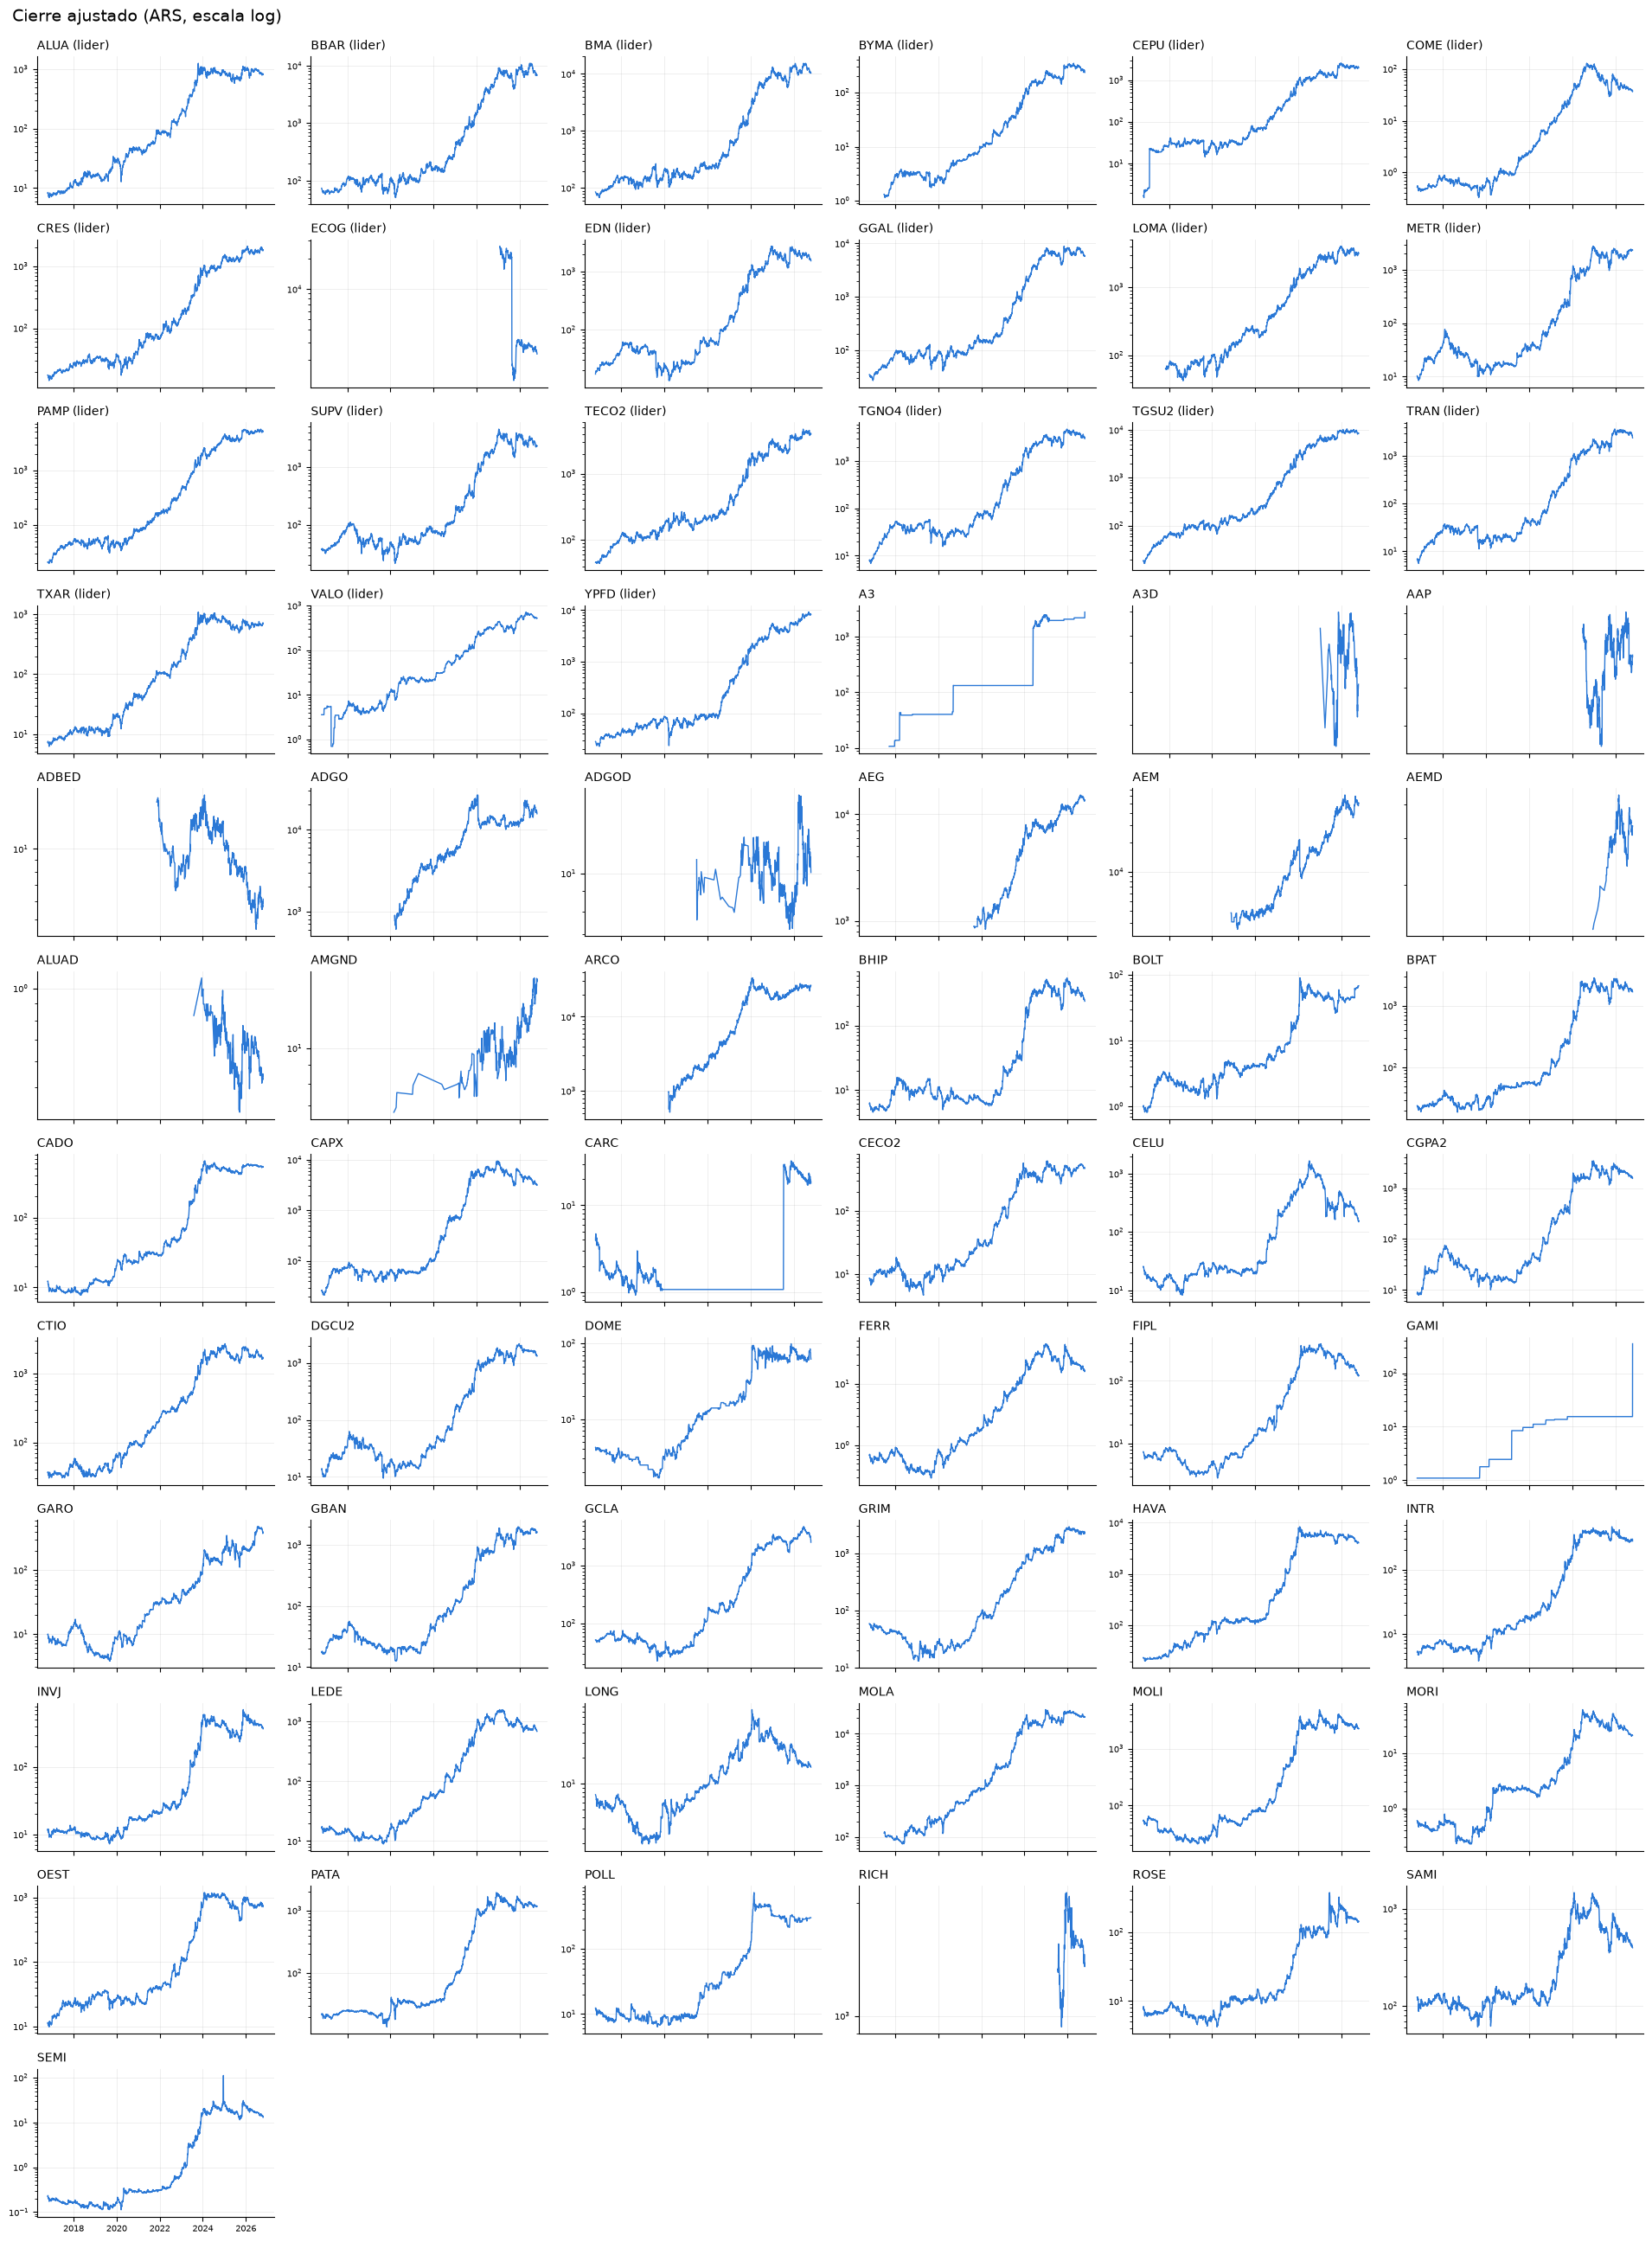

In [10]:
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter

# Cierre ajustado historico de cada accion; primero el panel lider, despues el resto.
# Eje Y en escala log: con la inflacion, en escala lineal los primeros anios quedan aplastados.
orden = info_tickers.sort_values(["panel_lider", "ticker"], ascending=[False, True])
n_cols = 6
n_filas = -(-len(orden) // n_cols)
fig, axes = plt.subplots(n_filas, n_cols, figsize=(3.2 * n_cols, 2.2 * n_filas), sharex=True)

for ax, (_, fila) in zip(axes.flat, orden.iterrows()):
    serie = precios.loc[precios["ticker"] == fila["ticker"]]
    ax.plot(serie["fecha"], serie["close"], color="#2a78d6", linewidth=1)
    ax.set_yscale("log")
    ax.yaxis.set_minor_formatter(NullFormatter())
    titulo = fila["ticker"] + (" (lider)" if fila["panel_lider"] else "")
    ax.set_title(titulo, fontsize=10, loc="left")
    ax.tick_params(labelsize=7)
    ax.grid(alpha=0.3, linewidth=0.5)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes.flat[len(orden):]:
    ax.set_visible(False)

fig.suptitle("Cierre ajustado (ARS, escala log)", fontsize=14, x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.985))
plt.show()

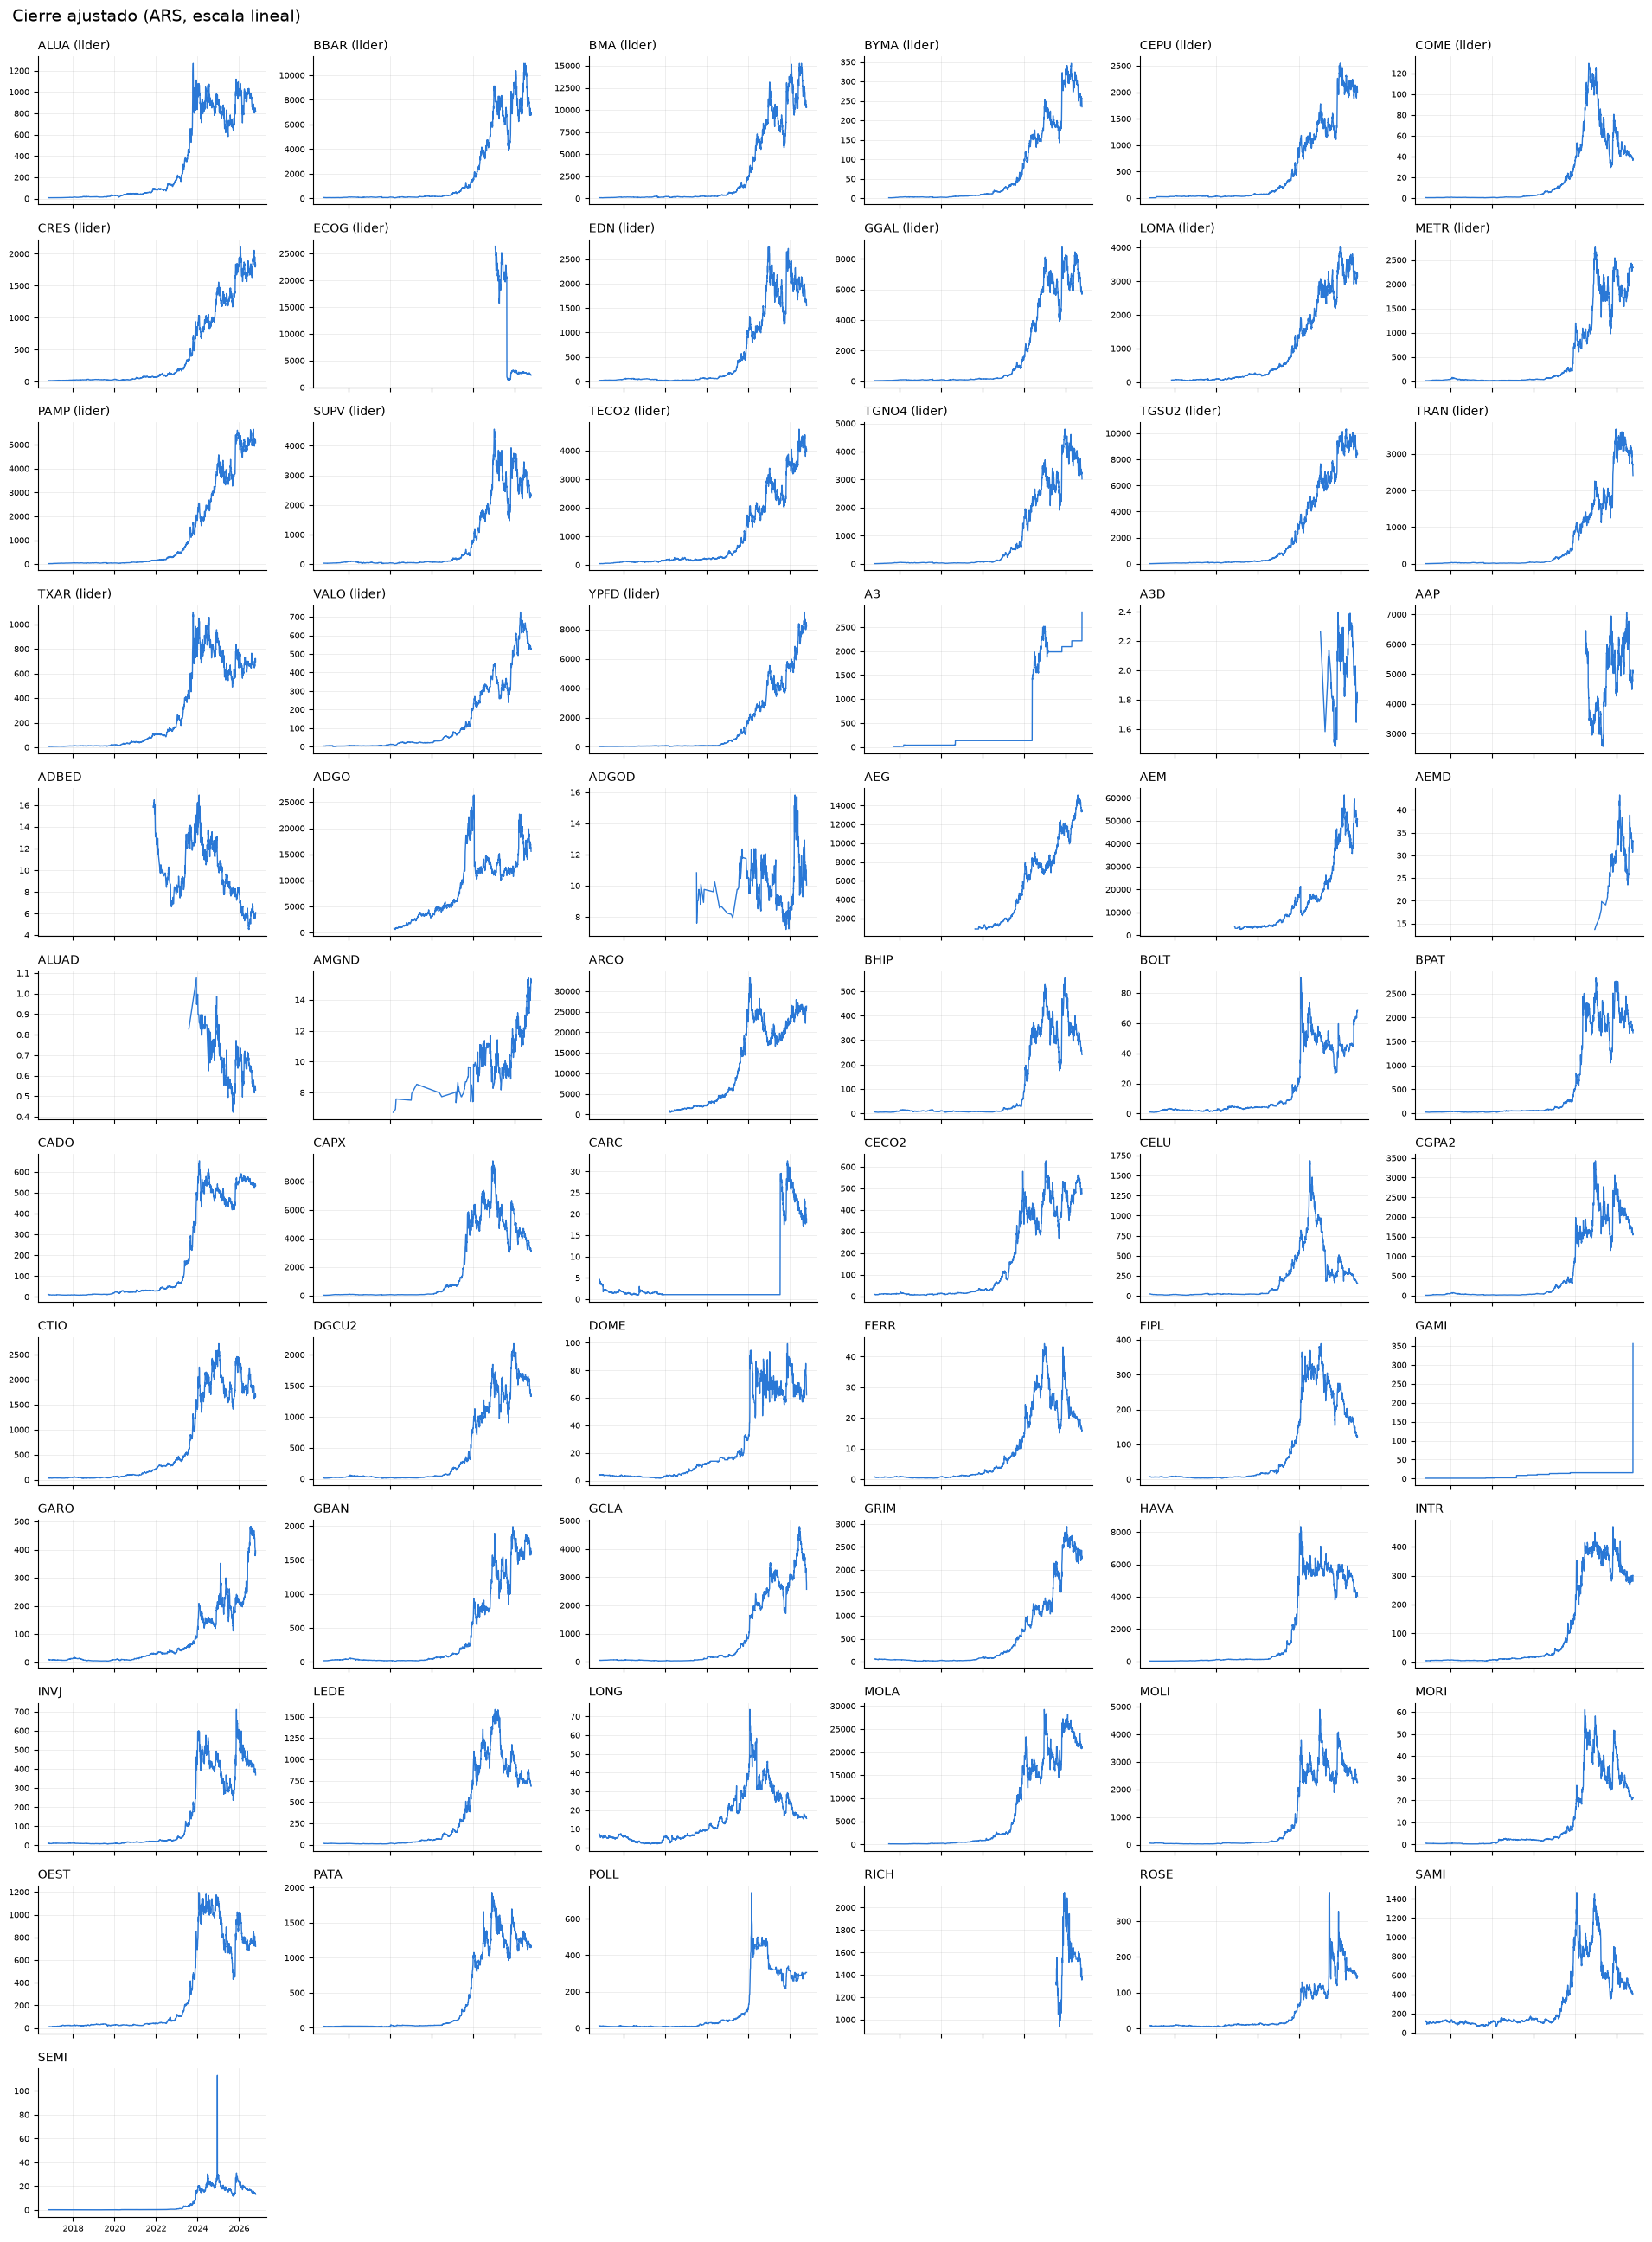

In [11]:
# Mismo grafico en escala lineal
fig, axes = plt.subplots(n_filas, n_cols, figsize=(3.2 * n_cols, 2.2 * n_filas), sharex=True)

for ax, (_, fila) in zip(axes.flat, orden.iterrows()):
    serie = precios.loc[precios["ticker"] == fila["ticker"]]
    ax.plot(serie["fecha"], serie["close"], color="#2a78d6", linewidth=1)
    titulo = fila["ticker"] + (" (lider)" if fila["panel_lider"] else "")
    ax.set_title(titulo, fontsize=10, loc="left")
    ax.tick_params(labelsize=7)
    ax.grid(alpha=0.3, linewidth=0.5)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes.flat[len(orden):]:
    ax.set_visible(False)

fig.suptitle("Cierre ajustado (ARS, escala lineal)", fontsize=14, x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.985))
plt.show()

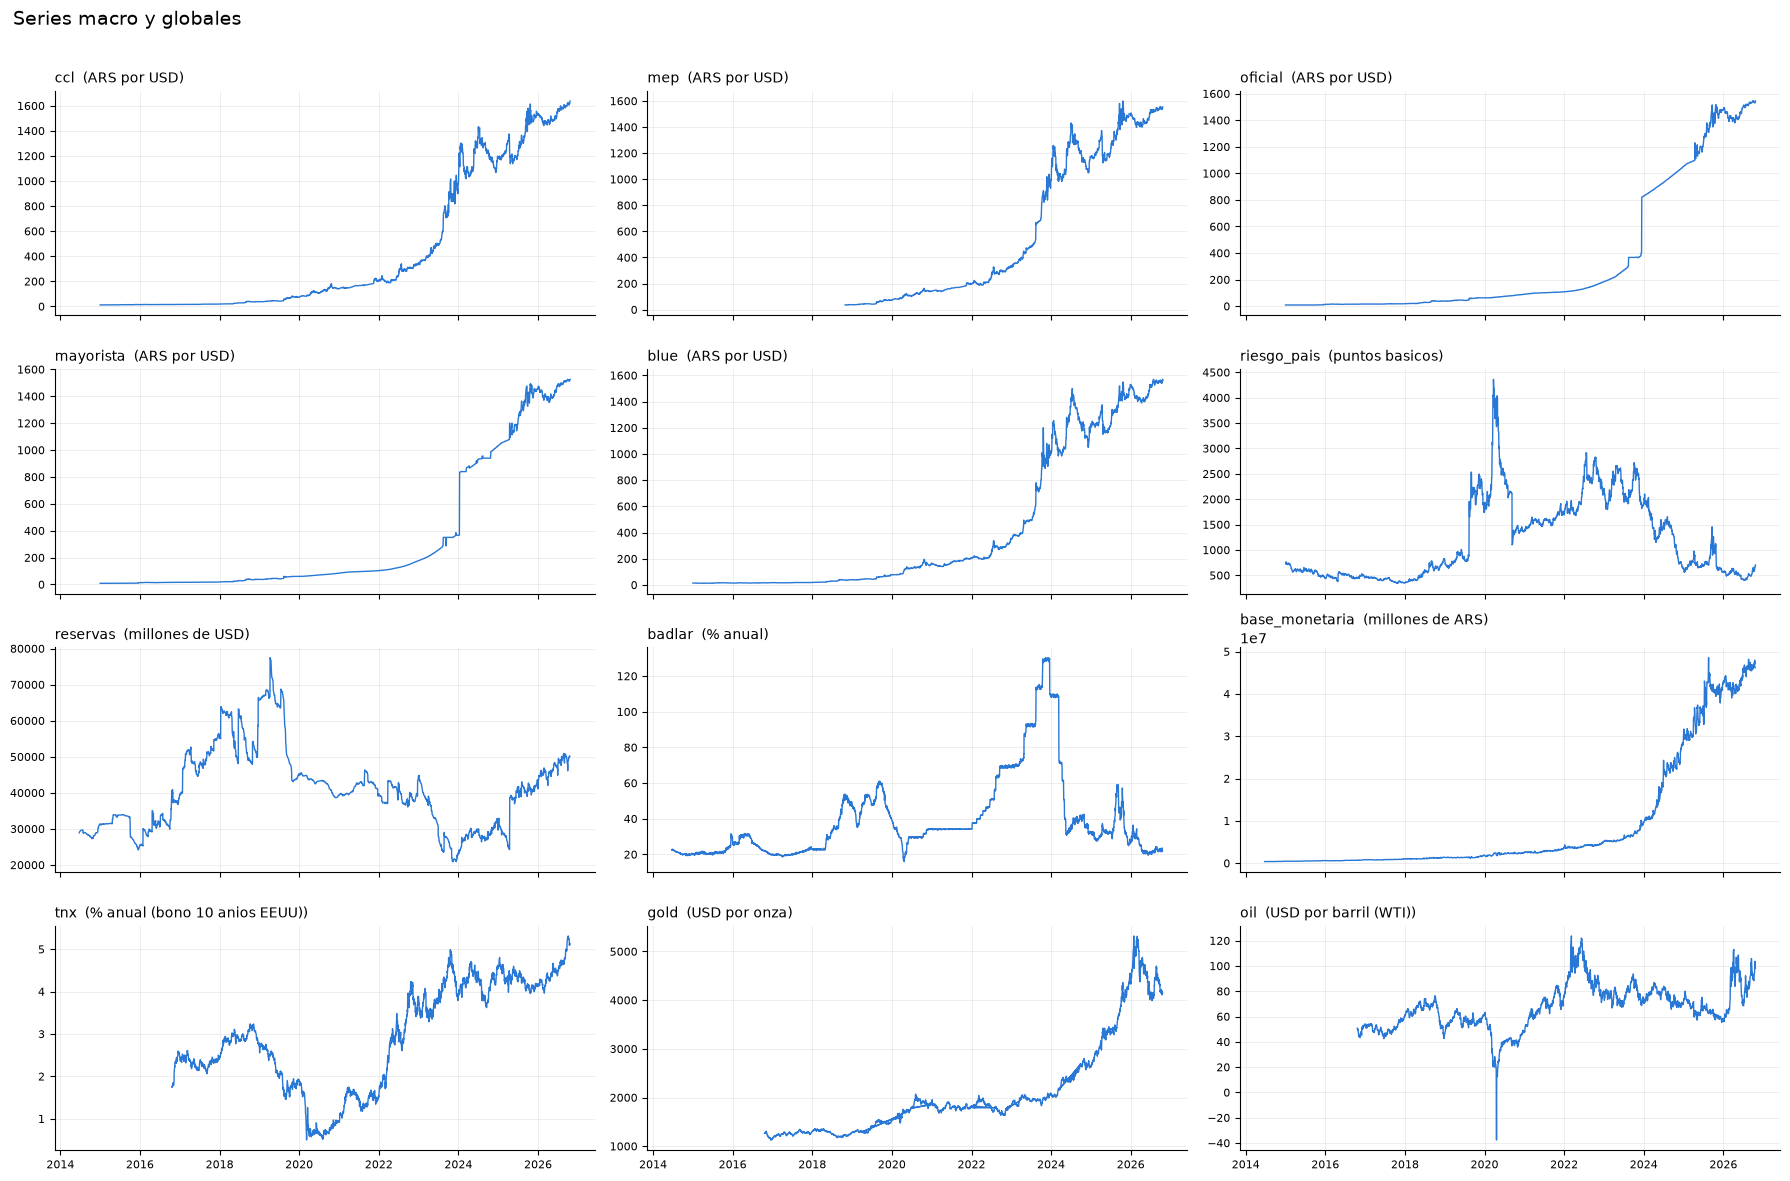

In [12]:
# Series macro y globales tal como las publica la fuente (sin el corrimiento por retraso)
UNIDADES = {
    "ccl": "ARS por USD",
    "mep": "ARS por USD",
    "oficial": "ARS por USD",
    "mayorista": "ARS por USD",
    "blue": "ARS por USD",
    "riesgo_pais": "puntos basicos",
    "reservas": "millones de USD",
    "badlar": "% anual",
    "base_monetaria": "millones de ARS",
    "tnx": "% anual (bono 10 anios EEUU)",
    "gold": "USD por onza",
    "oil": "USD por barril (WTI)",
}
n_cols_macro = 3
n_filas_macro = -(-len(macro_cruda) // n_cols_macro)
fig, axes = plt.subplots(n_filas_macro, n_cols_macro, figsize=(6 * n_cols_macro, 3 * n_filas_macro), sharex=True)

for ax, (nombre, serie) in zip(axes.flat, macro_cruda.items()):
    ax.plot(serie.index, serie.values, color="#2a78d6", linewidth=1)
    ax.set_title(f"{nombre}  ({UNIDADES[nombre]})", fontsize=10, loc="left")
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.3, linewidth=0.5)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes.flat[len(macro_cruda):]:
    ax.set_visible(False)

fig.suptitle("Series macro y globales", fontsize=14, x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

In [13]:
# Precios en dolares usando el CCL del mismo dia (ultimo publicado si ese dia no hay dato).
# Aca no se aplica el retraso de publicacion: es para valuar, no una feature del modelo.
# Las especies en dolares ya cotizan en USD y se dejan como estan.
ccl_dia = macro_cruda["ccl"].rename("ccl_dia").rename_axis("fecha").reset_index()
dataset = pd.merge_asof(
    dataset.drop(columns="ccl_dia", errors="ignore").sort_values("fecha"),
    ccl_dia,
    on="fecha",
    direction="backward",
).sort_values(["ticker", "fecha"]).reset_index(drop=True)

for col in ["open", "high", "low", "close"]:
    dataset[f"{col}_usd"] = np.where(dataset["en_dolares"], dataset[col], dataset[col] / dataset["ccl_dia"])

dataset.loc[dataset["ticker"] == "GGAL", ["fecha", "ticker", "close", "ccl_dia", "close_usd"]].tail()

,fecha,ticker,close,ccl_dia,close_usd
76739,2026-10-14,GGAL,5750.0,1613.8,3.563019
76740,2026-10-15,GGAL,5900.0,1617.3,3.648055
76741,2026-10-16,GGAL,5805.0,1616.0,3.592203
76742,2026-10-19,GGAL,5690.0,1620.5,3.511262
76743,2026-10-20,GGAL,5765.0,1625.6,3.546383


In [14]:
dataset.head()

,fecha,ticker,open,high,low,close,close_unadj,volume,sector,panel_lider,en_dolares,ccl,mep,oficial,mayorista,blue,riesgo_pais,reservas,badlar,base_monetaria,tnx,gold,oil,ccl_dia,open_usd,high_usd,low_usd,close_usd
0,2017-09-20,A3,10.616164,10.616164,10.616164,10.616164,12.258630,70124.0,Financials,False,False,17.04,NaN,17.0,17.13,18.0,370.0,51024.0,21.3750,845236.0,2.243,1306.199951,49.480000,17.19,0.617578,0.617578,0.617578,0.617578
1,2017-09-21,A3,10.657633,10.657633,10.657633,10.657633,12.306515,70124.0,Financials,False,False,17.19,NaN,17.0,17.17,18.0,371.0,51024.0,21.3750,845236.0,2.277,1312.000000,50.410000,17.26,0.617476,0.617476,0.617476,0.617476
2,2017-09-22,A3,10.657633,10.657633,10.657633,10.657633,12.306515,0.0,Financials,False,False,17.19,NaN,17.0,17.22,18.0,370.0,51024.0,21.3750,845236.0,2.278,1290.599976,50.549999,17.33,0.614982,0.614982,0.614982,0.614982
3,2017-09-25,A3,10.657633,10.657633,10.657633,10.657633,12.306515,0.0,Financials,False,False,17.33,NaN,18.0,17.34,18.0,368.0,51366.0,21.6250,926112.0,2.262,1293.300049,50.660000,17.39,0.612860,0.612860,0.612860,0.612860
4,2017-09-26,A3,10.657633,10.657633,10.657633,10.657633,12.306515,0.0,Financials,False,False,17.33,NaN,18.0,17.34,18.0,368.0,51292.0,21.5625,920080.0,2.220,1306.800049,52.220001,17.55,0.607273,0.607273,0.607273,0.607273


In [15]:
# def detectar_outliers(
#     df: pd.DataFrame,
#     max_pct_plano: float = 40.0,
#     max_salto: float = 1.0,
#     ruedas_recorte: int = 150,
# ) -> pd.DataFrame:
#     """Marca tickers con datos poco confiables y que hacer con cada uno.

#     - ``excluir``: mas de ``max_pct_plano`` % de ruedas con el precio sin cambio (casi no
#       opera, Yahoo repite el ultimo precio), o algun retorno log diario en USD mayor a
#       ``max_salto`` en valor absoluto (split sin ajustar o dato malo).
#     - ``recortar``: si todos esos saltos caen en las primeras ``ruedas_recorte`` ruedas del
#       ticker, se conserva la historia posterior al ultimo salto.
#     """
#     df = df.sort_values(["ticker", "fecha"])
#     aux = df[["ticker", "fecha"]].assign(
#         r=np.log(df["close_usd"]).groupby(df["ticker"]).diff().abs(),
#         plano=df.groupby("ticker")["close"].diff().eq(0),
#         pos=df.groupby("ticker").cumcount(),
#     )
#     filas = []
#     for ticker, g in aux.groupby("ticker"):
#         pct_plano = g["plano"].mean() * 100
#         saltos = g.loc[g["r"] > max_salto]
#         fechas = ", ".join(saltos["fecha"].dt.strftime("%Y-%m-%d"))
#         desde = pd.NaT
#         if pct_plano > max_pct_plano:
#             accion, motivo = "excluir", f"{pct_plano:.0f}% de ruedas sin cambio de precio"
#         elif saltos.empty:
#             continue
#         elif saltos["pos"].max() < ruedas_recorte:
#             accion, motivo = "recortar", f"salto al inicio ({fechas})"
#             desde = g.loc[g["pos"] > saltos["pos"].max(), "fecha"].min()
#         else:
#             accion, motivo = "excluir", f"salto diario > {max_salto} log ({fechas})"
#         filas.append({"ticker": ticker, "accion": accion, "motivo": motivo, "desde": desde})
#     return pd.DataFrame(filas, columns=["ticker", "accion", "motivo", "desde"])


# outliers = detectar_outliers(dataset)

# excluidos = outliers.loc[outliers["accion"] == "excluir", "ticker"]
# dataset = dataset[~dataset["ticker"].isin(excluidos)]
# for _, fila in outliers[outliers["accion"] == "recortar"].iterrows():
#     dataset = dataset[~((dataset["ticker"] == fila["ticker"]) & (dataset["fecha"] < fila["desde"]))]
# dataset = dataset.reset_index(drop=True)

# # El indice de mercado cambia sin los outliers: se recalcula el beta
# dataset["beta_252"] = beta_rolling(dataset)

# print(f"{dataset['ticker'].nunique()} tickers, {len(dataset)} filas")
# outliers

Yahoo: 2214 ruedas, 203 con volumen > 0
Ultima rueda con volumen: 2025-02-28


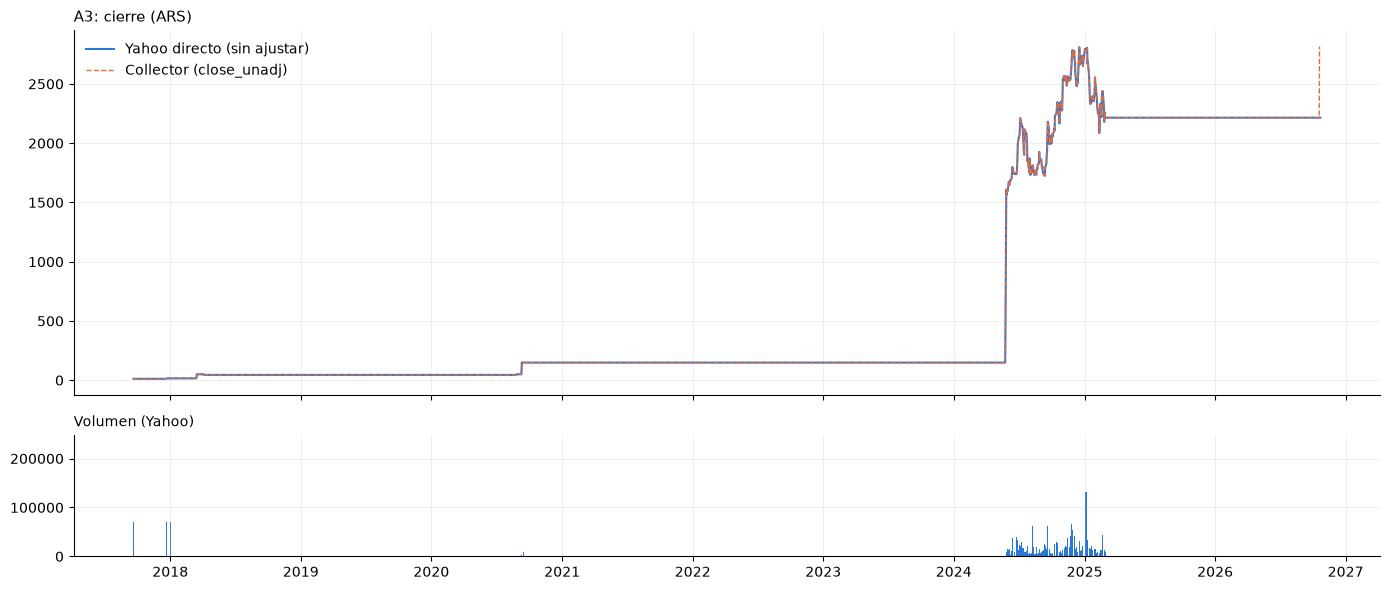

A3 reconstruida: factor Rava/BYMA 1.0419, 199 ruedas de Rava + 485 de BYMA


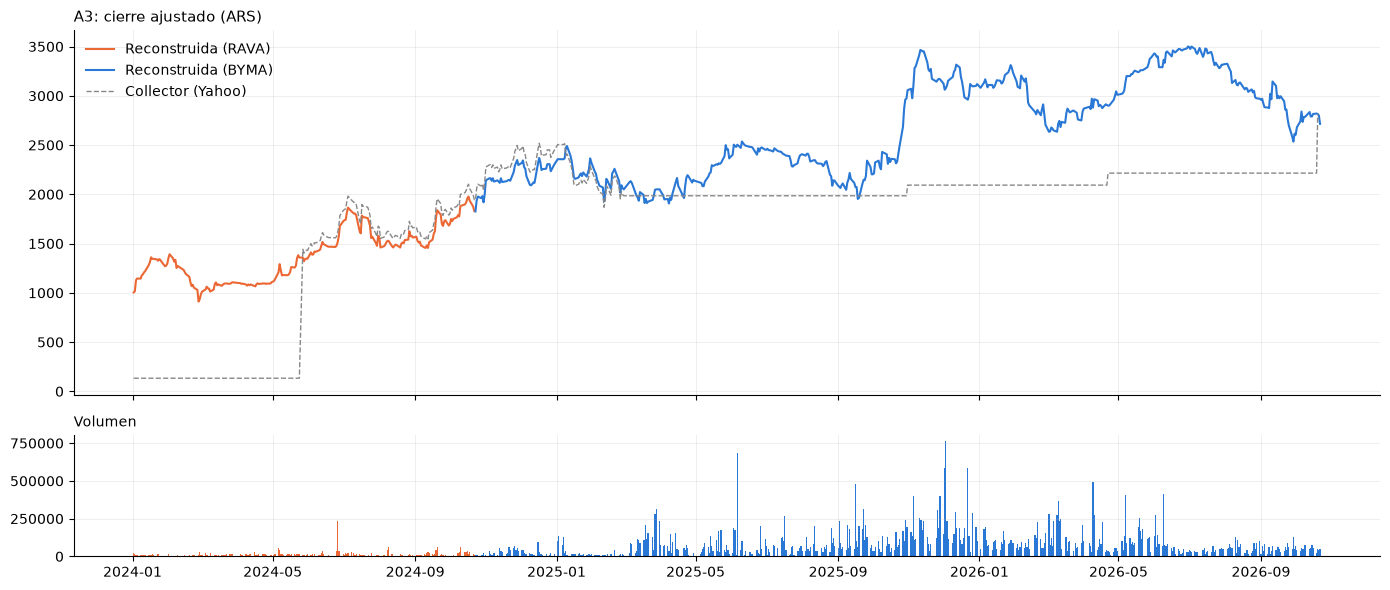

In [16]:
def reconstruir(ticker: str, ruedas_solape: int = 60, desde: str | None = None) -> pd.DataFrame:
    BYMA_HISTORICO_URL = "https://open.bymadata.com.ar/vanoms-be-core/rest/api/bymadata/free/chart/historical-series/history"
    RAVA_HISTORICO_URL = "https://mercado.rava.com/api/prices/historico/arg/{ticker}"
    import time
    """Historico de ``ticker`` armado con BYMA y Rava, con el mismo formato que ``precios``.

    Para tickers donde Yahoo viene mal (ej. A3: dejo de actualizar en feb-2025; Rava ademas
    tiene cierres erroneos en mar-2026):
    - desde que hay datos en BYMA se usa BYMA (limpio y ajustado por dividendos);
    - antes, Rava dividida por la mediana de la razon Rava/BYMA en las primeras
      ``ruedas_solape`` ruedas en comun, para llevarla a la misma base ajustada.
    - ``desde`` recorta la historia de Rava (ej. al inicio del resto del dataset).
    ``close_unadj`` queda vacio: BYMA solo da precios ajustados.
    """
    def bajar_rava(ticker: str) -> pd.DataFrame:
        """OHLCV diario de Rava, sin ajustar. Puede traer maximo/minimo/apertura vacios."""
        resp = requests.get(RAVA_HISTORICO_URL.format(ticker=ticker), params={"dias": 4435}, timeout=TIMEOUT)
        resp.raise_for_status()
        r = pd.DataFrame(resp.json()["datos"])
        r.index = pd.to_datetime(r["fecha"].str[:10]).rename("fecha")
        return r.rename(
            columns={"apertura": "open", "maximo": "high", "minimo": "low", "precio": "close", "volumen": "volume"}
        )[["open", "high", "low", "close", "volume"]].sort_index()

    def bajar_byma(ticker: str, anios: int = 3) -> pd.DataFrame:
        """OHLCV diario de BYMA (plazo 24hs), ajustado por dividendos. La API gratis da ~2 anios."""
        ahora = int(time.time())
        resp = requests.get(
            BYMA_HISTORICO_URL,
            params={"symbol": f"{ticker} 24HS", "resolution": "D", "from": ahora - 86400 * 365 * anios, "to": ahora},
            headers={"User-Agent": "Mozilla/5.0"},
            timeout=TIMEOUT,
        )
        resp.raise_for_status()
        b = resp.json()
        return pd.DataFrame(
            {"open": b["o"], "high": b["h"], "low": b["l"], "close": b["c"], "volume": b["v"]},
            index=_a_fecha([t * 1000 for t in b["t"]]).rename("fecha"),
        )
        
    byma = bajar_byma(ticker)
    rava = bajar_rava(ticker)
    if desde is not None:
        rava = rava.loc[rava.index >= pd.Timestamp(desde)]
    solape = pd.concat([rava["close"], byma["close"]], axis=1, keys=["rava", "byma"], join="inner")
    factor = (solape["rava"] / solape["byma"]).iloc[:ruedas_solape].median()

    previo = rava.loc[rava.index < byma.index.min()]
    previo = previo[["open", "high", "low", "close"]].div(factor).assign(volume=previo["volume"])
    serie = pd.concat([previo.assign(fuente="rava"), byma.assign(fuente="byma")]).sort_index()
    serie = serie.assign(ticker=ticker, close_unadj=np.nan).reset_index()
    serie[["open", "high", "low", "close", "volume"]] = serie[["open", "high", "low", "close", "volume"]].astype(float)
    print(f"{ticker} reconstruida: factor Rava/BYMA {factor:.4f}, {len(previo)} ruedas de Rava + {len(byma)} de BYMA")
    return serie[["fecha", "ticker", "open", "high", "low", "close", "close_unadj", "volume", "fuente"]]

a3 = reconstruir("A3")

# Comparacion contra lo que trae el collector (Yahoo, cierre ajustado)
a3_collector = precios.loc[precios["ticker"] == "A3"].set_index("fecha")
desde = a3["fecha"].min()
fig, (ax_p, ax_v) = plt.subplots(2, 1, figsize=(14, 6), sharex=True, height_ratios=[3, 1])
for fuente, color in [("rava", "#eb6834"), ("byma", "#2a78d6")]:
    tramo = a3[a3["fuente"] == fuente]
    ax_p.plot(tramo["fecha"], tramo["close"], color=color, linewidth=1.5, label=f"Reconstruida ({fuente.upper()})")
    ax_v.bar(tramo["fecha"], tramo["volume"], width=1, color=color)
ax_p.plot(a3_collector.loc[desde:].index, a3_collector.loc[desde:, "close"], color="#888888", linewidth=1, linestyle="--", label="Collector (Yahoo)")
ax_p.set_title("A3: cierre ajustado (ARS)", fontsize=11, loc="left")
ax_p.legend(frameon=False)
ax_v.set_title("Volumen", fontsize=10, loc="left")
for ax in (ax_p, ax_v):
    ax.grid(alpha=0.3, linewidth=0.5)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

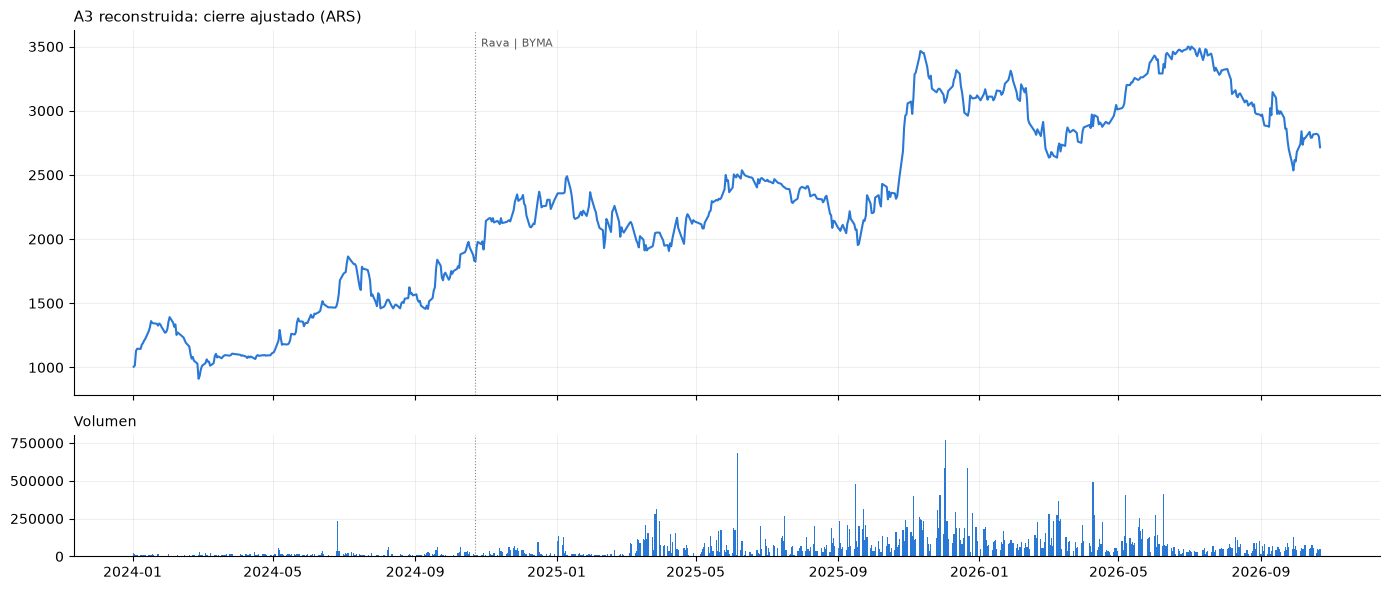

In [17]:
# A3 reconstruida completa: cierre ajustado y volumen
empalme = a3.loc[a3["fuente"] == "byma", "fecha"].min()
fig, (ax_p, ax_v) = plt.subplots(2, 1, figsize=(14, 6), sharex=True, height_ratios=[3, 1])
ax_p.plot(a3["fecha"], a3["close"], color="#2a78d6", linewidth=1.5)
ax_p.set_title("A3 reconstruida: cierre ajustado (ARS)", fontsize=11, loc="left")
ax_v.bar(a3["fecha"], a3["volume"], width=1, color="#2a78d6")
ax_v.set_title("Volumen", fontsize=10, loc="left")
for ax in (ax_p, ax_v):
    ax.axvline(empalme, color="#888888", linewidth=0.8, linestyle=":")
    ax.grid(alpha=0.3, linewidth=0.5)
    ax.spines[["top", "right"]].set_visible(False)
ax_p.annotate("Rava | BYMA", xy=(empalme, 1), xycoords=("data", "axes fraction"), xytext=(4, -12), textcoords="offset points", fontsize=8, color="#555555")
fig.tight_layout()
plt.show()

In [18]:
def quitar_picos(df: pd.DataFrame, max_salto: float = 1.0) -> pd.DataFrame:
    """Reemplaza por el cierre anterior las ruedas aisladas que saltan y vuelven al dia siguiente.

    Es el caso de SEMI el 2024-12-16: Yahoo ajusto el split ~4:1 del 17-12 hacia atras pero no ese dia.
    """
    df = df.sort_values("fecha").copy()
    r = np.log(df["close"]).diff()
    pico = (r.abs() > max_salto) & (r.shift(-1).abs() > max_salto) & (np.sign(r) != np.sign(r.shift(-1)))
    cols = ["open", "high", "low", "close", "close_unadj"]
    df.loc[pico, cols] = np.nan
    df[cols] = df[cols].ffill()
    return df


# Que hacer con cada outlier (ver detectar_outliers y el relevamiento de BYMA/Rava)
RECONSTRUIR = ["A3", "CARC", "DOME", "ECOG", "GAMI", "RICH"]  # BYMA + Rava limpios
PICOS = ["SEMI"]  # Yahoo esta bien salvo una rueda
# Desde cuando la serie es confiable: CEPU y VALO tienen saltos y ruedas sin volumen al inicio en Yahoo,
# DOME en Rava tiene solo 3 ruedas sueltas antes de 2024
RECORTAR = {"CEPU": "2017-02-06", "VALO": "2017-08-01", "DOME": "2024-01-02"}
EXCLUIR = ["POLL"]  # poco liquida en todas las fuentes (71% de ruedas planas en BYMA)

inicio = precios["fecha"].min()
reconstruidas = [reconstruir(t, desde=inicio).drop(columns="fuente") for t in RECONSTRUIR]
corregidas = [quitar_picos(precios[precios["ticker"] == t]) for t in PICOS]

precios = pd.concat(
    [precios[~precios["ticker"].isin(RECONSTRUIR + PICOS + EXCLUIR)], *reconstruidas, *corregidas],
    ignore_index=True,
)
for ticker, desde in RECORTAR.items():
    precios = precios[~((precios["ticker"] == ticker) & (precios["fecha"] < pd.Timestamp(desde)))]
precios = precios.sort_values(["ticker", "fecha"]).reset_index(drop=True)

resumen = precios[precios["ticker"].isin(set(RECONSTRUIR + PICOS) | set(RECORTAR))].groupby("ticker").agg(
    ruedas=("fecha", "size"), desde=("fecha", "min"), hasta=("fecha", "max")
)
print(f"{precios['ticker'].nunique()} tickers, {len(precios)} filas")
resumen

A3 reconstruida: factor Rava/BYMA 1.0419, 199 ruedas de Rava + 485 de BYMA


CARC reconstruida: factor Rava/BYMA 1.0000, 1952 ruedas de Rava + 486 de BYMA


DOME reconstruida: factor Rava/BYMA 1.0000, 178 ruedas de Rava + 486 de BYMA


ECOG reconstruida: factor Rava/BYMA 10.4037, 0 ruedas de Rava + 429 de BYMA


GAMI reconstruida: factor Rava/BYMA 1.0000, 1291 ruedas de Rava + 486 de BYMA


RICH reconstruida: factor Rava/BYMA 1.0208, 1650 ruedas de Rava + 486 de BYMA
66 tickers, 136333 filas


,ruedas,desde,hasta
ticker,,,
A3,684,2024-01-02,2026-10-22
CARC,2438,2016-10-20,2026-10-22
CEPU,2365,2017-02-06,2026-10-20
DOME,661,2024-01-02,2026-10-22
ECOG,429,2025-01-21,2026-10-22
GAMI,1777,2019-06-26,2026-10-22
RICH,2136,2017-12-22,2026-10-22
SEMI,2439,2016-10-20,2026-10-20
VALO,2247,2017-08-01,2026-10-20


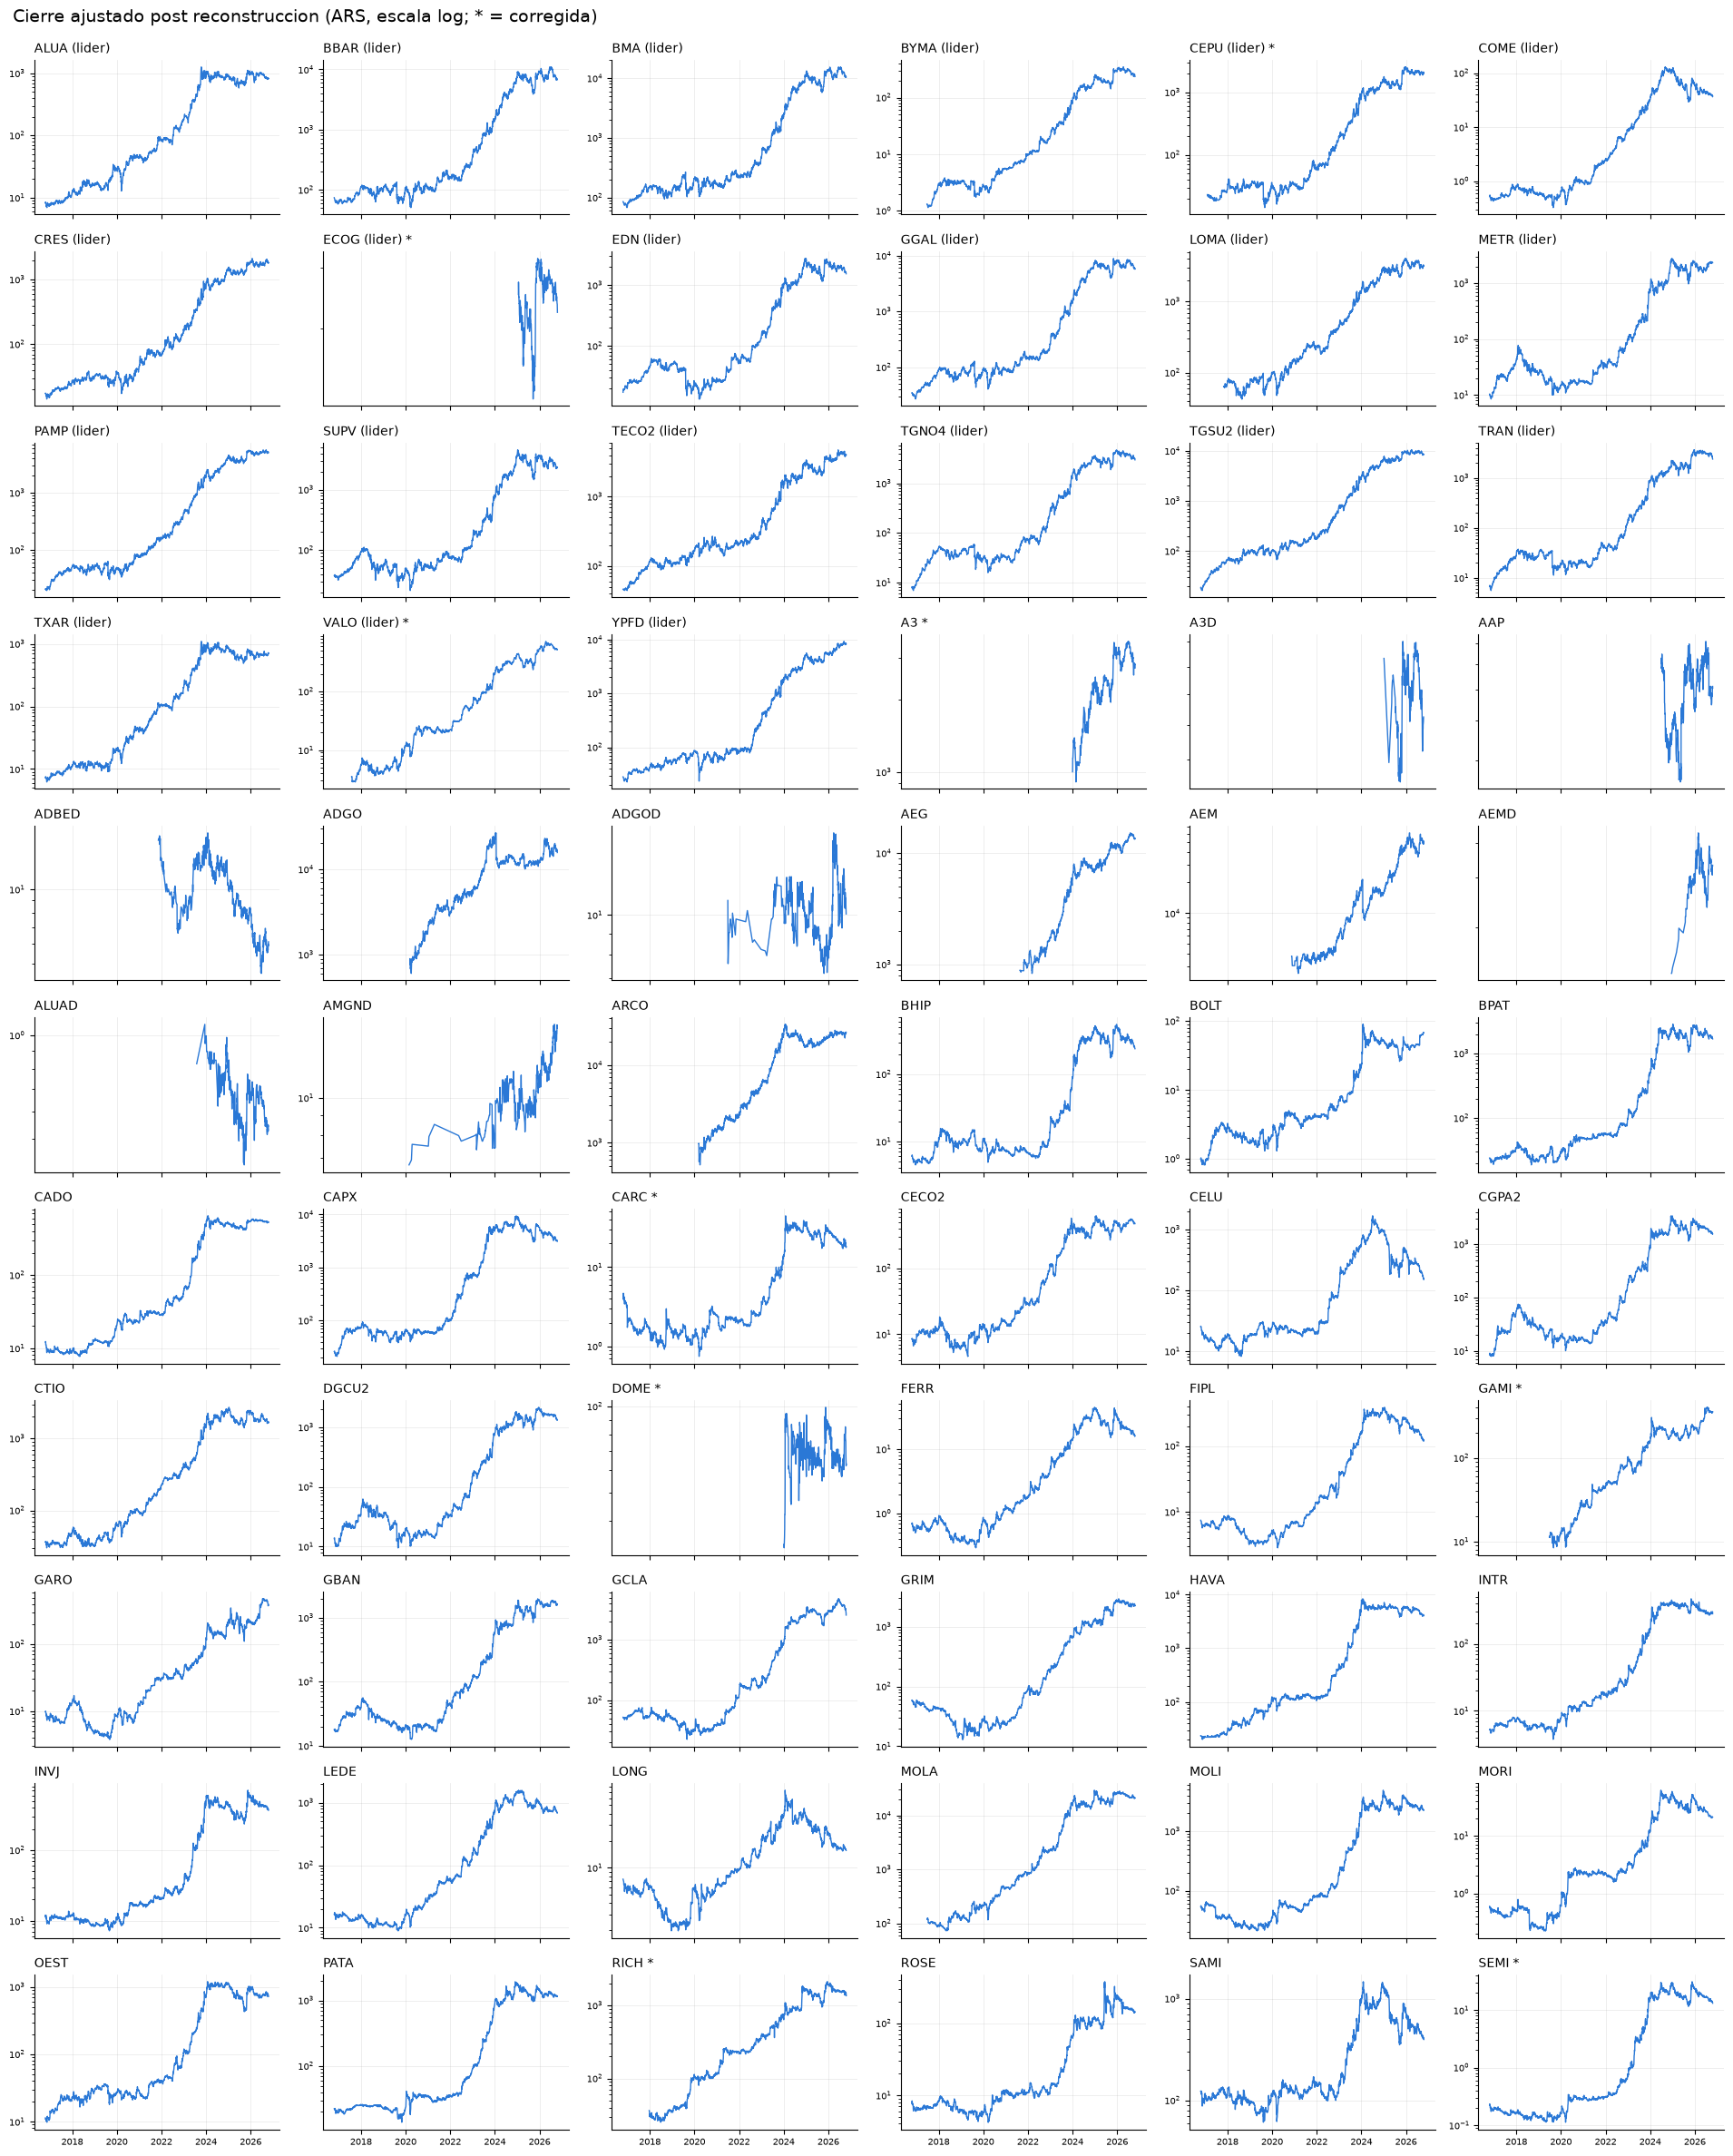

In [19]:
# Cierre ajustado de todas las acciones despues de las reconstrucciones (escala log)
orden = info_tickers[info_tickers["ticker"].isin(precios["ticker"].unique())].sort_values(
    ["panel_lider", "ticker"], ascending=[False, True]
)
n_filas = -(-len(orden) // n_cols)
fig, axes = plt.subplots(n_filas, n_cols, figsize=(3.2 * n_cols, 2.2 * n_filas), sharex=True)

for ax, (_, fila) in zip(axes.flat, orden.iterrows()):
    serie = precios.loc[precios["ticker"] == fila["ticker"]]
    corregido = fila["ticker"] in RECONSTRUIR + PICOS + list(RECORTAR)
    ax.plot(serie["fecha"], serie["close"], color="#2a78d6", linewidth=1)
    ax.set_yscale("log")
    ax.yaxis.set_minor_formatter(NullFormatter())
    titulo = fila["ticker"] + (" (lider)" if fila["panel_lider"] else "") + (" *" if corregido else "")
    ax.set_title(titulo, fontsize=10, loc="left")
    ax.tick_params(labelsize=7)
    ax.grid(alpha=0.3, linewidth=0.5)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes.flat[len(orden):]:
    ax.set_visible(False)

fig.suptitle("Cierre ajustado post reconstruccion (ARS, escala log; * = corregida)", fontsize=14, x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.985))
plt.show()

In [20]:
def armar_dataset(precios: pd.DataFrame) -> pd.DataFrame:
    """Panel fecha x ticker con los mismos pasos de arriba: sector y marcas, macro alineada
    con su retraso y precios en USD con el CCL del dia."""
    marcas = info_tickers[["ticker", "sector", "panel_lider", "en_dolares"]]
    df = (
        precios.merge(marcas, on="ticker", how="left")
        .merge(alinear_macro(precios["fecha"]), on="fecha", how="left")
        .sort_values("fecha")
    )
    ccl_dia = macro_cruda["ccl"].rename("ccl_dia").rename_axis("fecha").reset_index()
    df = pd.merge_asof(df, ccl_dia, on="fecha", direction="backward")
    df = df.sort_values(["ticker", "fecha"]).reset_index(drop=True)
    for col in ["open", "high", "low", "close"]:
        df[f"{col}_usd"] = np.where(df["en_dolares"], df[col], df[col] / df["ccl_dia"])
    return df


dataset = armar_dataset(precios)
print(dataset.shape)
print(f"{dataset['ticker'].nunique()} tickers, {dataset['fecha'].min().date()} -> {dataset['fecha'].max().date()}")
(dataset.isna().mean() * 100).round(2).loc[lambda s: s > 0]

(136333, 28)
66 tickers, 2016-10-20 -> 2026-10-22


open            0.02
high            0.02
low             0.02
close_unadj     5.96
volume          0.02
sector          7.00
mep            17.75
tnx             0.03
gold            0.03
oil             0.03
open_usd        0.02
high_usd        0.02
low_usd         0.02
dtype: float64

In [21]:
def beta_rolling(
    df: pd.DataFrame,
    ventana: int = 252,
    min_ruedas: int = 126,
    col_precio: str = "close_usd",
) -> pd.Series:
    """Beta rolling de cada accion contra un indice armado con el panel lider.

    El "mercado" es el promedio simple de los retornos log diarios de las acciones
    del panel lider (no hay ^MERV en el collector ni capitalizacion para ponderar).
    El beta en la fecha t usa solo retornos hasta t. Devuelve una serie alineada con ``df``.
    """
    df = df.sort_values(["ticker", "fecha"])
    retorno = np.log(df[col_precio]).groupby(df["ticker"]).diff()
    mercado = retorno[df["panel_lider"]].groupby(df.loc[df["panel_lider"], "fecha"]).mean()
    r_mercado = df["fecha"].map(mercado)

    def _beta(grupo: pd.DataFrame) -> pd.Series:
        r, m = grupo["r"], grupo["m"]
        cov = r.rolling(ventana, min_periods=min_ruedas).cov(m)
        var = m.rolling(ventana, min_periods=min_ruedas).var()
        return cov / var

    partes = pd.DataFrame({"r": retorno, "m": r_mercado, "ticker": df["ticker"]})
    beta = partes.groupby("ticker", group_keys=False)[["r", "m"]].apply(_beta)
    return beta.reindex(df.index)


dataset["beta_252"] = beta_rolling(dataset)

# Beta mas reciente de cada accion del panel lider
ultimo = dataset.dropna(subset=["beta_252"]).groupby("ticker").tail(1)
ultimo.loc[ultimo["panel_lider"], ["ticker", "fecha", "beta_252"]].sort_values("beta_252", ascending=False).round({"beta_252": 2})

,ticker,fecha,beta_252
119451,SUPV,2026-10-20,1.53
15111,BBAR,2026-10-20,1.34
93091,METR,2026-10-20,1.28
57423,EDN,2026-10-20,1.26
19989,BMA,2026-10-20,1.22
46577,COME,2026-10-20,1.21
73834,GGAL,2026-10-20,1.17
124329,TGNO4,2026-10-20,1.15
41699,CEPU,2026-10-20,1.13
121890,TECO2,2026-10-20,1.03


Matriz 78x78 (66 acciones + 12 otros activos)


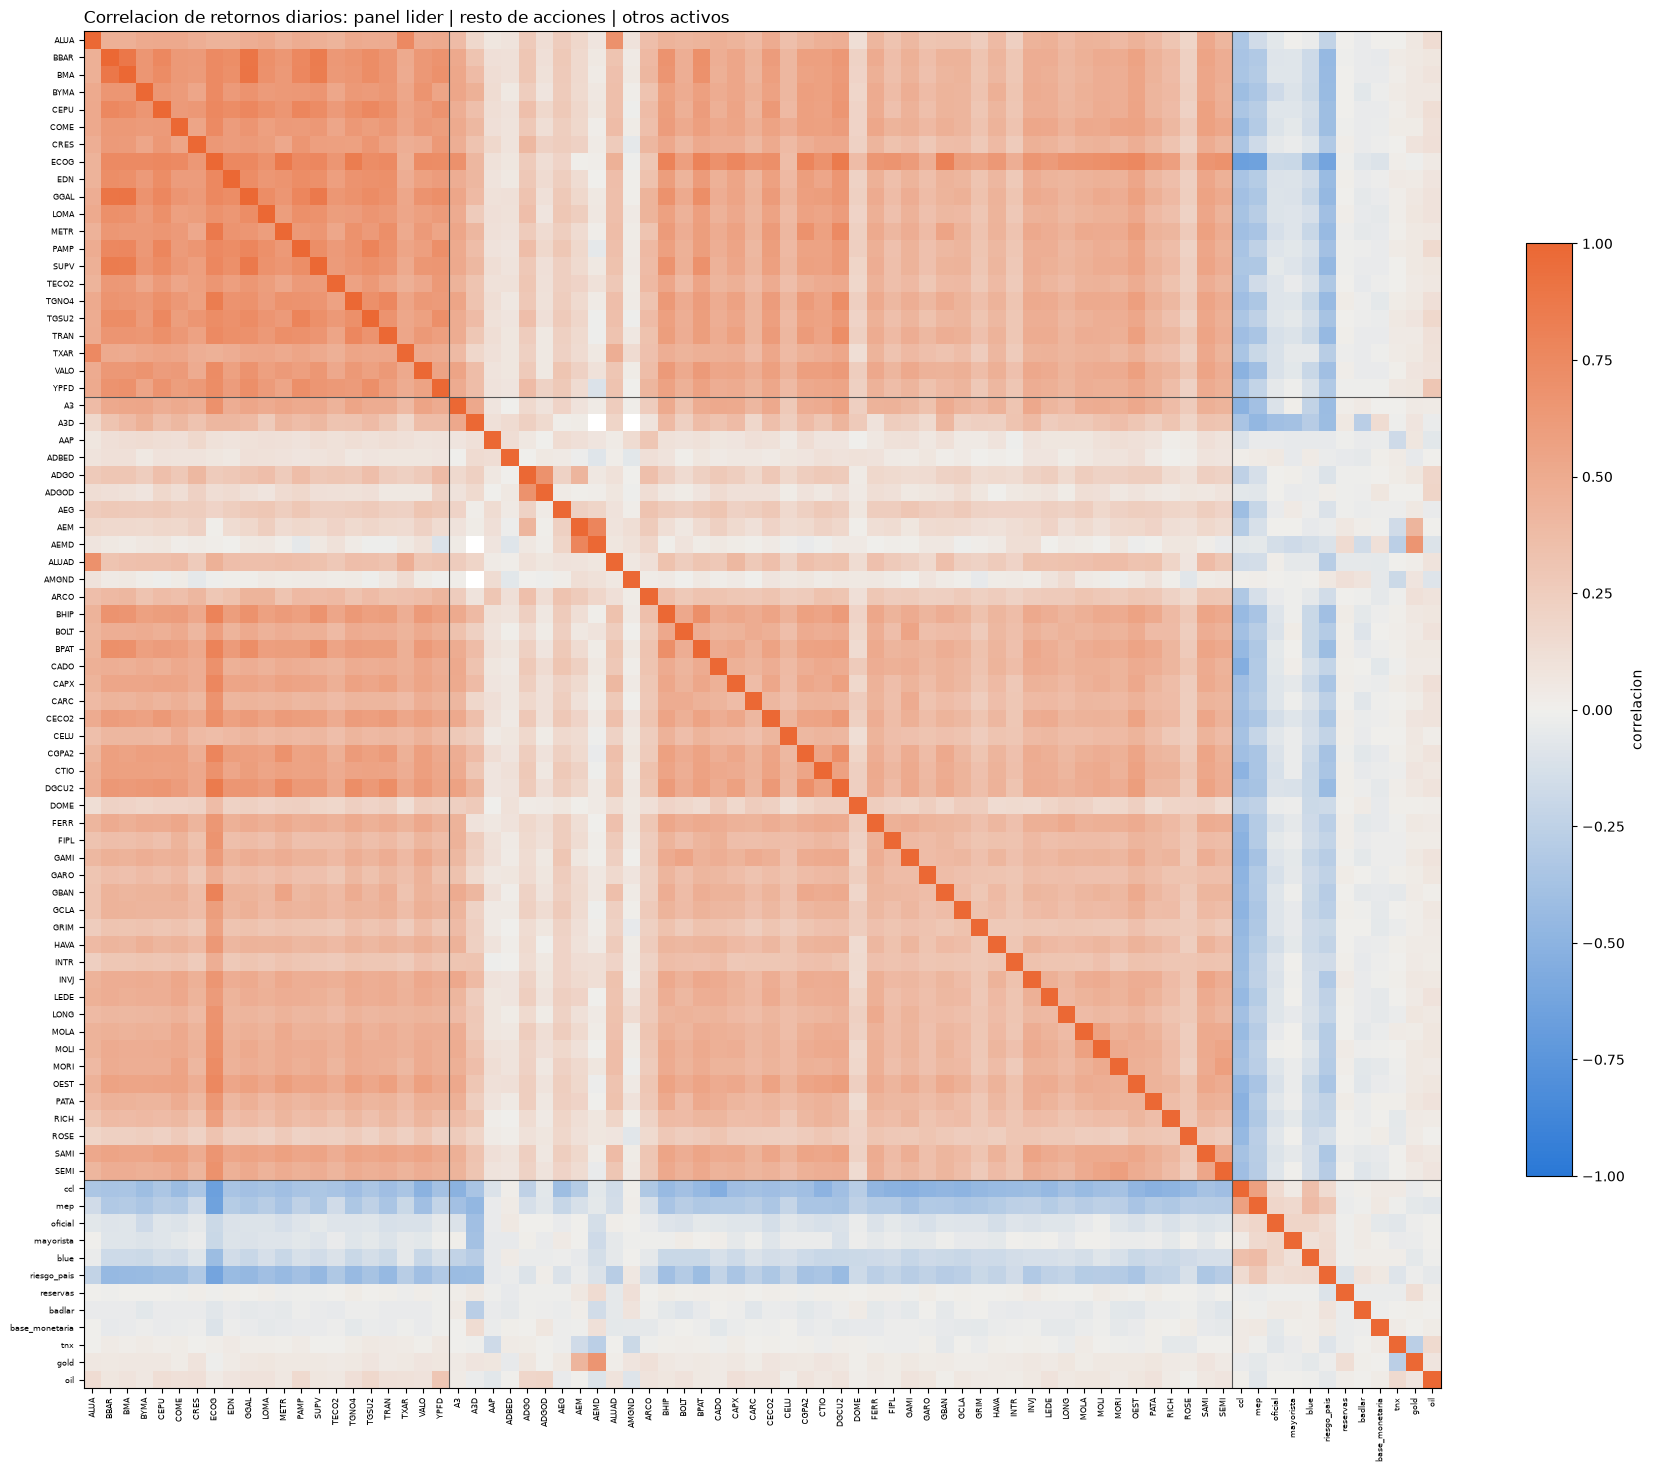

,ALUA,BBAR,BMA,BYMA,CEPU,COME,CRES,ECOG,EDN,GGAL,LOMA,METR,PAMP,SUPV,TECO2,TGNO4,TGSU2,TRAN,TXAR,VALO,YPFD,A3,A3D,AAP,ADBED,...,INTR,INVJ,LEDE,LONG,MOLA,MOLI,MORI,OEST,PATA,RICH,ROSE,SAMI,SEMI,ccl,mep,oficial,mayorista,blue,riesgo_pais,reservas,badlar,base_monetaria,tnx,gold,oil
ALUA,0.001050,0.000633,0.000624,0.000574,0.000650,0.000590,0.000521,0.000570,0.000579,0.000624,0.000629,0.000652,0.000548,0.000678,0.000477,0.000660,0.000576,0.000661,0.000793,0.000528,0.000584,3.242119e-04,0.000164,0.000082,0.000079,...,0.000274,0.000503,0.000468,0.000475,0.000524,0.000508,0.000523,0.000508,0.000399,0.000366,0.000261,0.000601,0.000508,-0.000201,-0.000089,-0.000037,8.579350e-07,-0.000014,-0.000250,1.257296e-06,-0.001499,-2.991754e-06,0.000009,2.125023e-05,0.000129
BBAR,0.000633,0.001760,0.001521,0.000968,0.001243,0.000941,0.000887,0.001409,0.001209,0.001489,0.001141,0.001200,0.001094,0.001602,0.000908,0.001137,0.001098,0.001151,0.000695,0.000884,0.001023,6.332579e-04,0.000455,0.000199,0.000146,...,0.000449,0.000713,0.000637,0.000652,0.000712,0.000746,0.000833,0.000817,0.000598,0.000611,0.000399,0.000826,0.000753,-0.000273,-0.000237,-0.000071,-7.210106e-05,-0.000119,-0.000621,-1.158654e-05,-0.001881,-5.174772e-05,0.000074,2.296976e-05,0.000079
BMA,0.000624,0.001521,0.001699,0.000946,0.001186,0.000916,0.000866,0.001311,0.001165,0.001485,0.001113,0.001146,0.001086,0.001563,0.000880,0.001086,0.001080,0.001124,0.000675,0.000868,0.001020,6.140630e-04,0.000504,0.000218,0.000139,...,0.000435,0.000698,0.000600,0.000625,0.000673,0.000714,0.000801,0.000781,0.000571,0.000574,0.000383,0.000795,0.000735,-0.000261,-0.000215,-0.000060,-7.156011e-05,-0.000120,-0.000596,4.814583e-07,-0.001752,-3.742023e-05,0.000048,2.511283e-05,0.000100
BYMA,0.000574,0.000968,0.000946,0.001182,0.000883,0.000763,0.000641,0.001037,0.000879,0.000951,0.000791,0.000983,0.000773,0.001048,0.000632,0.000896,0.000778,0.000933,0.000613,0.000743,0.000685,5.008761e-04,0.000411,0.000179,0.000058,...,0.000388,0.000605,0.000517,0.000542,0.000565,0.000601,0.000674,0.000662,0.000468,0.000493,0.000357,0.000673,0.000604,-0.000267,-0.000197,-0.000106,-6.869941e-05,-0.000105,-0.000502,1.419011e-06,-0.003202,-1.817025e-05,0.000061,2.262973e-05,0.000060
CEPU,0.000650,0.001243,0.001186,0.000883,0.001520,0.000865,0.000858,0.001171,0.001150,0.001195,0.001039,0.001134,0.001046,0.001300,0.000832,0.001109,0.001073,0.001132,0.000714,0.000770,0.000951,4.761135e-04,0.000420,0.000173,0.000107,...,0.000427,0.000655,0.000583,0.000614,0.000639,0.000687,0.000761,0.000753,0.000526,0.000542,0.000355,0.000800,0.000687,-0.000244,-0.000189,-0.000061,-6.852526e-05,-0.000086,-0.000531,-1.239478e-06,-0.001921,-4.218280e-05,0.000049,2.593925e-05,0.000140
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
badlar,-0.001499,-0.001881,-0.001752,-0.003202,-0.001921,-0.001794,-0.001532,-0.004193,-0.002088,-0.002702,-0.002064,-0.003127,-0.001060,-0.002043,-0.002124,-0.001168,-0.001107,-0.002025,-0.001447,-0.001731,-0.000692,2.155746e-03,-0.011805,-0.002041,-0.003241,...,-0.002070,-0.001659,-0.001343,-0.001849,-0.002462,-0.000836,-0.003441,-0.003283,-0.001103,-0.001549,-0.000878,-0.002284,-0.003934,0.000379,-0.000308,0.000798,8.999093e-04,0.000413,0.003560,-5.845069e-04,1.791037,-7.443865e-04,0.000251,1.861574e-04,0.000055
base_monetaria,-0.000003,-0.000052,-0.000037,-0.000018,-0.000042,-0.000030,-0.000017,-0.000106,-0.000024,-0.000042,-0.000052,-0.000054,-0.000036,-0.000043,-0.000020,-0.000066,-0.000029,-0.000040,-0.000011,-0.000031,-0.000015,-1.742585e-06,0.000087,-0.000032,0.000007,...,-0.000017,-0.000009,-0.000042,-0.000050,-0.000027,-0.000008,-0.000061,-0.000037,0.000010,0.000005,0.000030,-0.000044,-0.000056,0.000020,0.000024,-0.000030,7.119761e-06,0.000009,0.000047,-1.166969e-05,-0.000744,7.619253e-04,0.000048,1.999265e-07,0.000021
tnx,0.000009,0.000074,0.000048,

In [22]:
from matplotlib.colors import LinearSegmentedColormap

# Matriz de covarianza de retornos diarios: acciones (log, en USD) y el resto de los activos.
# Para los otros activos se usa el valor del mismo dia (sin retraso de publicacion):
# log-retorno para precios y niveles, diferencia simple para tasas (BADLAR y TNX ya son %).
TASAS = {"badlar", "tnx"}

r_acciones = np.log(dataset.pivot(index="fecha", columns="ticker", values="close_usd")).diff()
r_acciones = r_acciones[orden["ticker"]]  # panel lider primero

fechas = r_acciones.index
otros = pd.DataFrame(
    {n: s.reindex(s.index.union(fechas)).ffill().reindex(fechas) for n, s in macro_cruda.items()}
)
r_otros = pd.DataFrame(
    # El petroleo cotizo negativo en abr-2020: ese dia el log-retorno no esta definido
    {n: otros[n].diff() if n in TASAS else np.log(otros[n].where(otros[n] > 0)).diff() for n in otros.columns}
)

retornos = pd.concat([r_acciones, r_otros], axis=1)
cov = retornos.cov(min_periods=126)  # por pares: cada par usa las fechas que tienen en comun
corr = retornos.corr(min_periods=126)
print(f"Matriz {cov.shape[0]}x{cov.shape[1]} ({r_acciones.shape[1]} acciones + {r_otros.shape[1]} otros activos)")

# La covarianza mezcla escalas muy distintas (un banco vs. la BADLAR), asi que para mirarla
# se grafica la correlacion, que es la covarianza normalizada; ``cov`` queda para usar.
cmap = LinearSegmentedColormap.from_list("divergente", ["#2a78d6", "#f0efec", "#eb6834"])
fig, ax = plt.subplots(figsize=(18, 16))
im = ax.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=6)
ax.set_yticks(range(len(corr)), corr.index, fontsize=6)
n_acc = r_acciones.shape[1]
for pos in (orden["panel_lider"].sum() - 0.5, n_acc - 0.5):
    ax.axhline(pos, color="#555555", linewidth=0.8)
    ax.axvline(pos, color="#555555", linewidth=0.8)
fig.colorbar(im, ax=ax, shrink=0.6, label="correlacion")
ax.set_title("Correlacion de retornos diarios: panel lider | resto de acciones | otros activos", fontsize=12, loc="left")
fig.tight_layout()
plt.show()

cov

Merval: 2430 ruedas, 2016-10-24 -> 2026-10-16


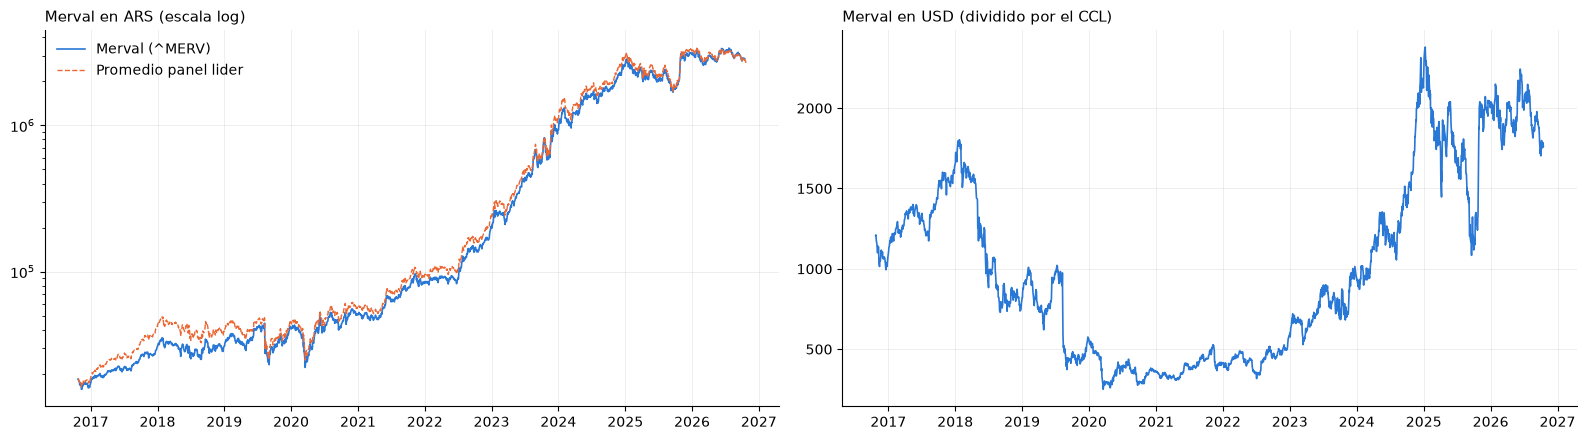

In [23]:
# Merval: el indice real (^MERV) se baja directo de Yahoo, el collector no lo tiene.
# Se compara con el indice que usa beta_rolling (promedio simple del panel lider) llevado a la misma base.
resp = requests.get(
    "https://query1.finance.yahoo.com/v8/finance/chart/%5EMERV",
    params={"range": "10y", "interval": "1d"},
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=TIMEOUT,
)
resp.raise_for_status()
res = resp.json()["chart"]["result"][0]
merval = pd.DataFrame(
    {"merval_ars": res["indicators"]["quote"][0]["close"]},
    index=_a_fecha([t * 1000 for t in res["timestamp"]]).rename("fecha"),
).dropna()
ccl_merval = macro_cruda["ccl"].reindex(macro_cruda["ccl"].index.union(merval.index)).ffill().reindex(merval.index)
merval["merval_usd"] = merval["merval_ars"] / ccl_merval

lider = dataset[dataset["panel_lider"]]
r_lider = np.log(lider.pivot(index="fecha", columns="ticker", values="close")).diff().mean(axis=1)
indice_lider = np.exp(r_lider.loc[merval.index.min():].fillna(0).cumsum()) * merval["merval_ars"].iloc[0]
print(f"Merval: {len(merval)} ruedas, {merval.index.min().date()} -> {merval.index.max().date()}")

fig, (ax_ars, ax_usd) = plt.subplots(1, 2, figsize=(16, 4.5))
ax_ars.plot(merval.index, merval["merval_ars"], color="#2a78d6", linewidth=1.2, label="Merval (^MERV)")
ax_ars.plot(indice_lider.index, indice_lider, color="#eb6834", linewidth=1, linestyle="--", label="Promedio panel lider")
ax_ars.set_yscale("log")
ax_ars.yaxis.set_minor_formatter(NullFormatter())
ax_ars.set_title("Merval en ARS (escala log)", fontsize=11, loc="left")
ax_ars.legend(frameon=False)
ax_usd.plot(merval.index, merval["merval_usd"], color="#2a78d6", linewidth=1.2)
ax_usd.set_title("Merval en USD (dividido por el CCL)", fontsize=11, loc="left")
for ax in (ax_ars, ax_usd):
    ax.grid(alpha=0.3, linewidth=0.5)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

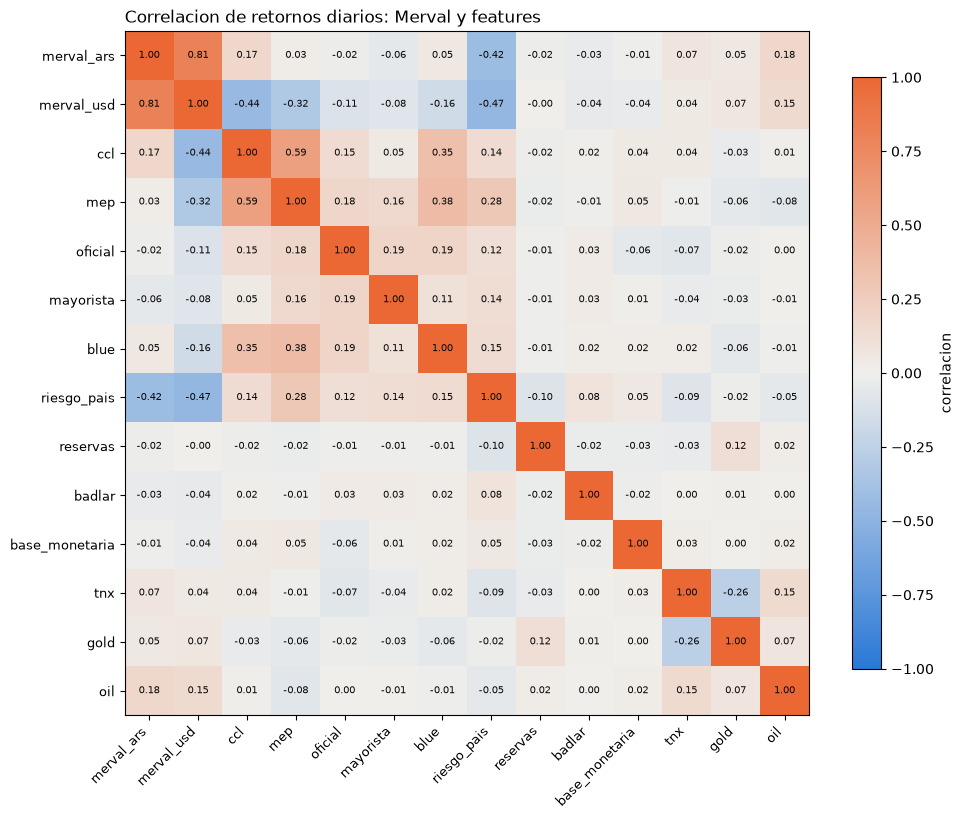

,merval_ars,merval_usd,ccl,mep,oficial,mayorista,blue,riesgo_pais,reservas,badlar,base_monetaria,tnx,gold,oil
merval_ars,7.74e-04,6.86e-04,8.83e-05,1.51e-05,-1.06e-05,-3.40e-05,2.42e-05,-3.85e-04,-8.13e-06,-1.26e-03,-8.60e-06,1.12e-04,1.56e-05,1.46e-04
merval_usd,6.86e-04,9.34e-04,-2.48e-04,-1.74e-04,-5.96e-05,-5.11e-05,-7.99e-05,-4.73e-04,-1.29e-06,-1.64e-03,-3.01e-05,6.86e-05,2.21e-05,1.39e-04
ccl,8.83e-05,-2.48e-04,3.37e-04,1.89e-04,4.90e-05,1.71e-05,1.04e-04,8.77e-05,-6.84e-06,3.81e-04,2.15e-05,4.37e-05,-6.53e-06,7.00e-06
mep,1.51e-05,-1.74e-04,1.89e-04,2.81e-04,5.64e-05,5.79e-05,1.07e-04,1.68e-04,-6.89e-06,-3.05e-04,2.41e-05,-1.12e-05,-1.14e-05,-4.18e-05
oficial,-1.06e-05,-5.96e-05,4.90e-05,5.64e-05,3.25e-04,7.16e-05,5.57e-05,7.10e-05,-2.93e-06,8.00e-04,-3.04e-05,-7.23e-05,-4.19e-06,2.43e-06
mayorista,-3.40e-05,-5.11e-05,1.71e-05,5.79e-05,7.16e-05,4.15e-04,3.57e-05,9.37e-05,-4.42e-06,9.06e-04,6.13e-06,-4.19e-05,-6.53e-06,-3.83e-06
blue,2.42e-05,-7.99e-05,1.04e-04,1.07e-04,5.57e-05,3.57e-05,2.64e-04,7.88e-05,-2.58e-06,4.42e-04,8.88e-06,1.91e-05,-1.01e-05,-4.37e-06
riesgo_pais,-3.85e-04,-4.73e-04,8.77e-05,1.68e-04,7.10e-05,9.37e-05,7.88e-05,1.09e-03,-5.62e-05,3.61e-03,4.75e-05,-1.60e-04,-7.66e-06,-4.85e-05
reservas,-8.13e-06,-1.29e-06,-6.84e-06,-6.89e-06,-2.93e-06,-4.42e-06,-2.58e-06,-5.62e-05,3.14e-04,-5.74e-04,-1.23e-05,-3.11e-05,2.30e-05,1.05e-05
badlar,-1.26e-03,-1.64e-03,3.81e-04,-3.05e-04,8.00e-04,9.06e-04,4.42e-04,3.61e-03,-5.74e-04,1.80e+00,-7.45e-04,3.18e-04,1.96e-04,8.15e-05


In [24]:
# Covarianza entre el Merval y las otras features (sin acciones), con retornos diarios del mismo dia:
# log-retorno para precios y niveles, diferencia simple para tasas (BADLAR y TNX ya son %).
TASAS = {"badlar", "tnx"}
fechas = merval.index
niveles = pd.DataFrame(
    {n: s.reindex(s.index.union(fechas)).ffill().reindex(fechas) for n, s in macro_cruda.items()}
)
niveles = pd.concat([merval[["merval_ars", "merval_usd"]], niveles], axis=1)
retornos_features = pd.DataFrame(
    # El petroleo cotizo negativo en abr-2020: ese dia el log-retorno no esta definido
    {n: niveles[n].diff() if n in TASAS else np.log(niveles[n].where(niveles[n] > 0)).diff() for n in niveles.columns}
)
cov_features = retornos_features.cov(min_periods=126)
corr_features = retornos_features.corr(min_periods=126)

# Las covarianzas tienen escalas muy distintas; para leerlas se grafica la correlacion con su valor
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr_features.values, cmap=cmap, vmin=-1, vmax=1)
etiquetas = corr_features.columns
ax.set_xticks(range(len(etiquetas)), etiquetas, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(etiquetas)), etiquetas, fontsize=9)
for i in range(len(etiquetas)):
    for j in range(len(etiquetas)):
        v = corr_features.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="#0b0b0b")
fig.colorbar(im, ax=ax, shrink=0.8, label="correlacion")
ax.set_title("Correlacion de retornos diarios: Merval y features", fontsize=12, loc="left")
fig.tight_layout()
plt.show()

with pd.option_context("display.float_format", "{:.2e}".format):
    display(cov_features)

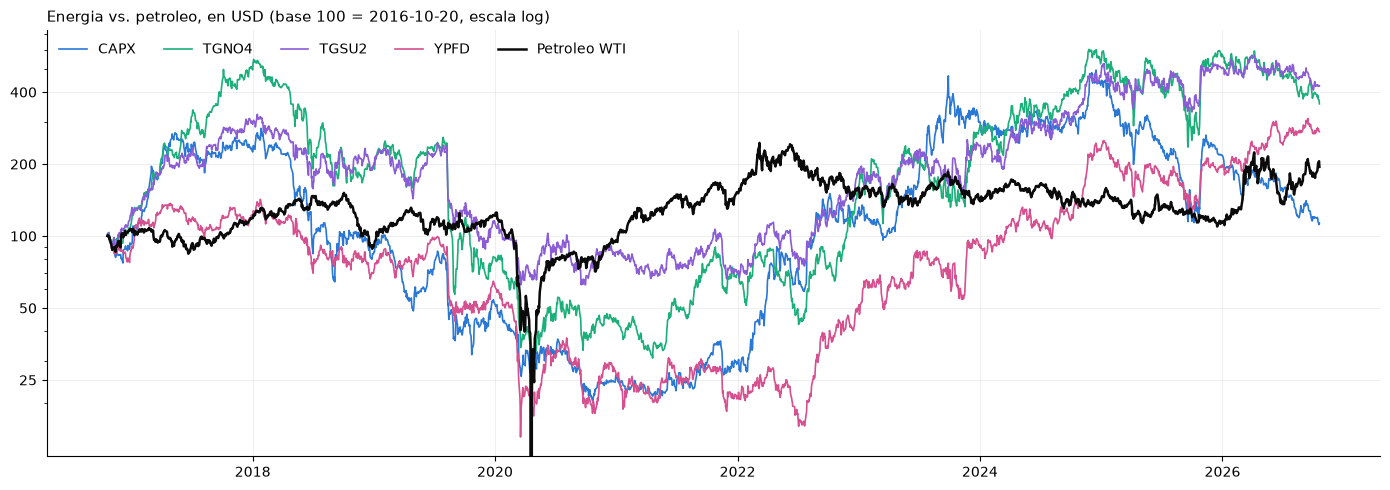

CAPX     0.11
TGNO4    0.11
TGSU2    0.17
YPFD     0.30
Name: corr con petroleo, dtype: float64

In [25]:
# Acciones del sector energia vs. petroleo (WTI), todo en USD y con base 100 en la primera fecha comun
energia = sorted(info_tickers.loc[info_tickers["sector"] == "Energy", "ticker"])
precios_energia = dataset[dataset["ticker"].isin(energia)].pivot(index="fecha", columns="ticker", values="close_usd")
comparacion = precios_energia.join(macro_cruda["oil"].rename("oil"), how="left")
comparacion["oil"] = comparacion["oil"].ffill()
comparacion = comparacion.loc[comparacion.dropna().index.min():]
base_100 = comparacion / comparacion.iloc[0] * 100

colores = ["#2a78d6", "#1baf7a", "#8a5cd6", "#d64f8e"]  # una por accion, en orden fijo
fig, ax = plt.subplots(figsize=(14, 5))
for ticker, color in zip(energia, colores):
    ax.plot(base_100.index, base_100[ticker], color=color, linewidth=1.2, label=ticker)
ax.plot(base_100.index, base_100["oil"], color="#0b0b0b", linewidth=1.8, label="Petroleo WTI")
ax.set_yscale("log")
ax.set_yticks([25, 50, 100, 200, 400], ["25", "50", "100", "200", "400"])
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_title(f"Energia vs. petroleo, en USD (base 100 = {base_100.index[0].date()}, escala log)", fontsize=11, loc="left")
ax.legend(frameon=False, ncol=5, loc="upper left")
ax.grid(alpha=0.3, linewidth=0.5)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

# Correlacion de retornos diarios de cada accion con el petroleo
r_energia = np.log(comparacion.where(comparacion > 0)).diff()
r_energia.corr()["oil"].drop("oil").round(2).rename("corr con petroleo")

In [26]:
def momentos(df: pd.DataFrame) -> pd.DataFrame:
    """Retorno log diario de cada accion en ARS y en USD, y su media y desvio de punta a punta
    (los parametros de Markowitz). La media y el desvio son un unico valor por ticker, calculado
    con toda su historia: sirven para describir, pero como feature de un modelo usan datos futuros.
    Las especies que cotizan en dolares se pasan a ARS con el CCL del dia.
    Devuelve un DataFrame alineado con ``df``.
    """
    df = df.sort_values(["ticker", "fecha"])
    precios_moneda = {
        "ars": pd.Series(np.where(df["en_dolares"], df["close"] * df["ccl_dia"], df["close"]), index=df.index),
        "usd": df["close_usd"],
    }
    salida = {}
    for moneda, precio in precios_moneda.items():
        retorno = np.log(precio).groupby(df["ticker"]).diff()
        por_ticker = retorno.groupby(df["ticker"])
        salida[f"retorno_{moneda}"] = retorno
        salida[f"media_{moneda}"] = por_ticker.transform("mean")
        salida[f"desvio_{moneda}"] = por_ticker.transform("std")
    return pd.DataFrame(salida).reindex(df.index)


columnas_momentos = ["retorno_ars", "media_ars", "desvio_ars", "retorno_usd", "media_usd", "desvio_usd"]
dataset = dataset.drop(columns=["retorno", "media_252", "desvio_252"], errors="ignore")
dataset[columnas_momentos] = momentos(dataset)
dataset.loc[dataset["ticker"] == "GGAL", ["fecha", "ticker", *columnas_momentos, "beta_252"]].tail()

,fecha,ticker,retorno_ars,media_ars,desvio_ars,retorno_usd,media_usd,desvio_usd,beta_252
73830,2026-10-14,GGAL,-0.032509,0.002095,0.036828,-0.036981,0.000181,0.039787,1.169905
73831,2026-10-15,GGAL,0.025752,0.002095,0.036828,0.023586,0.000181,0.039787,1.169855
73832,2026-10-16,GGAL,-0.016233,0.002095,0.036828,-0.015429,0.000181,0.039787,1.170139
73833,2026-10-19,GGAL,-0.020009,0.002095,0.036828,-0.022790,0.000181,0.039787,1.172724
73834,2026-10-20,GGAL,0.013095,0.002095,0.036828,0.009953,0.000181,0.039787,1.172441


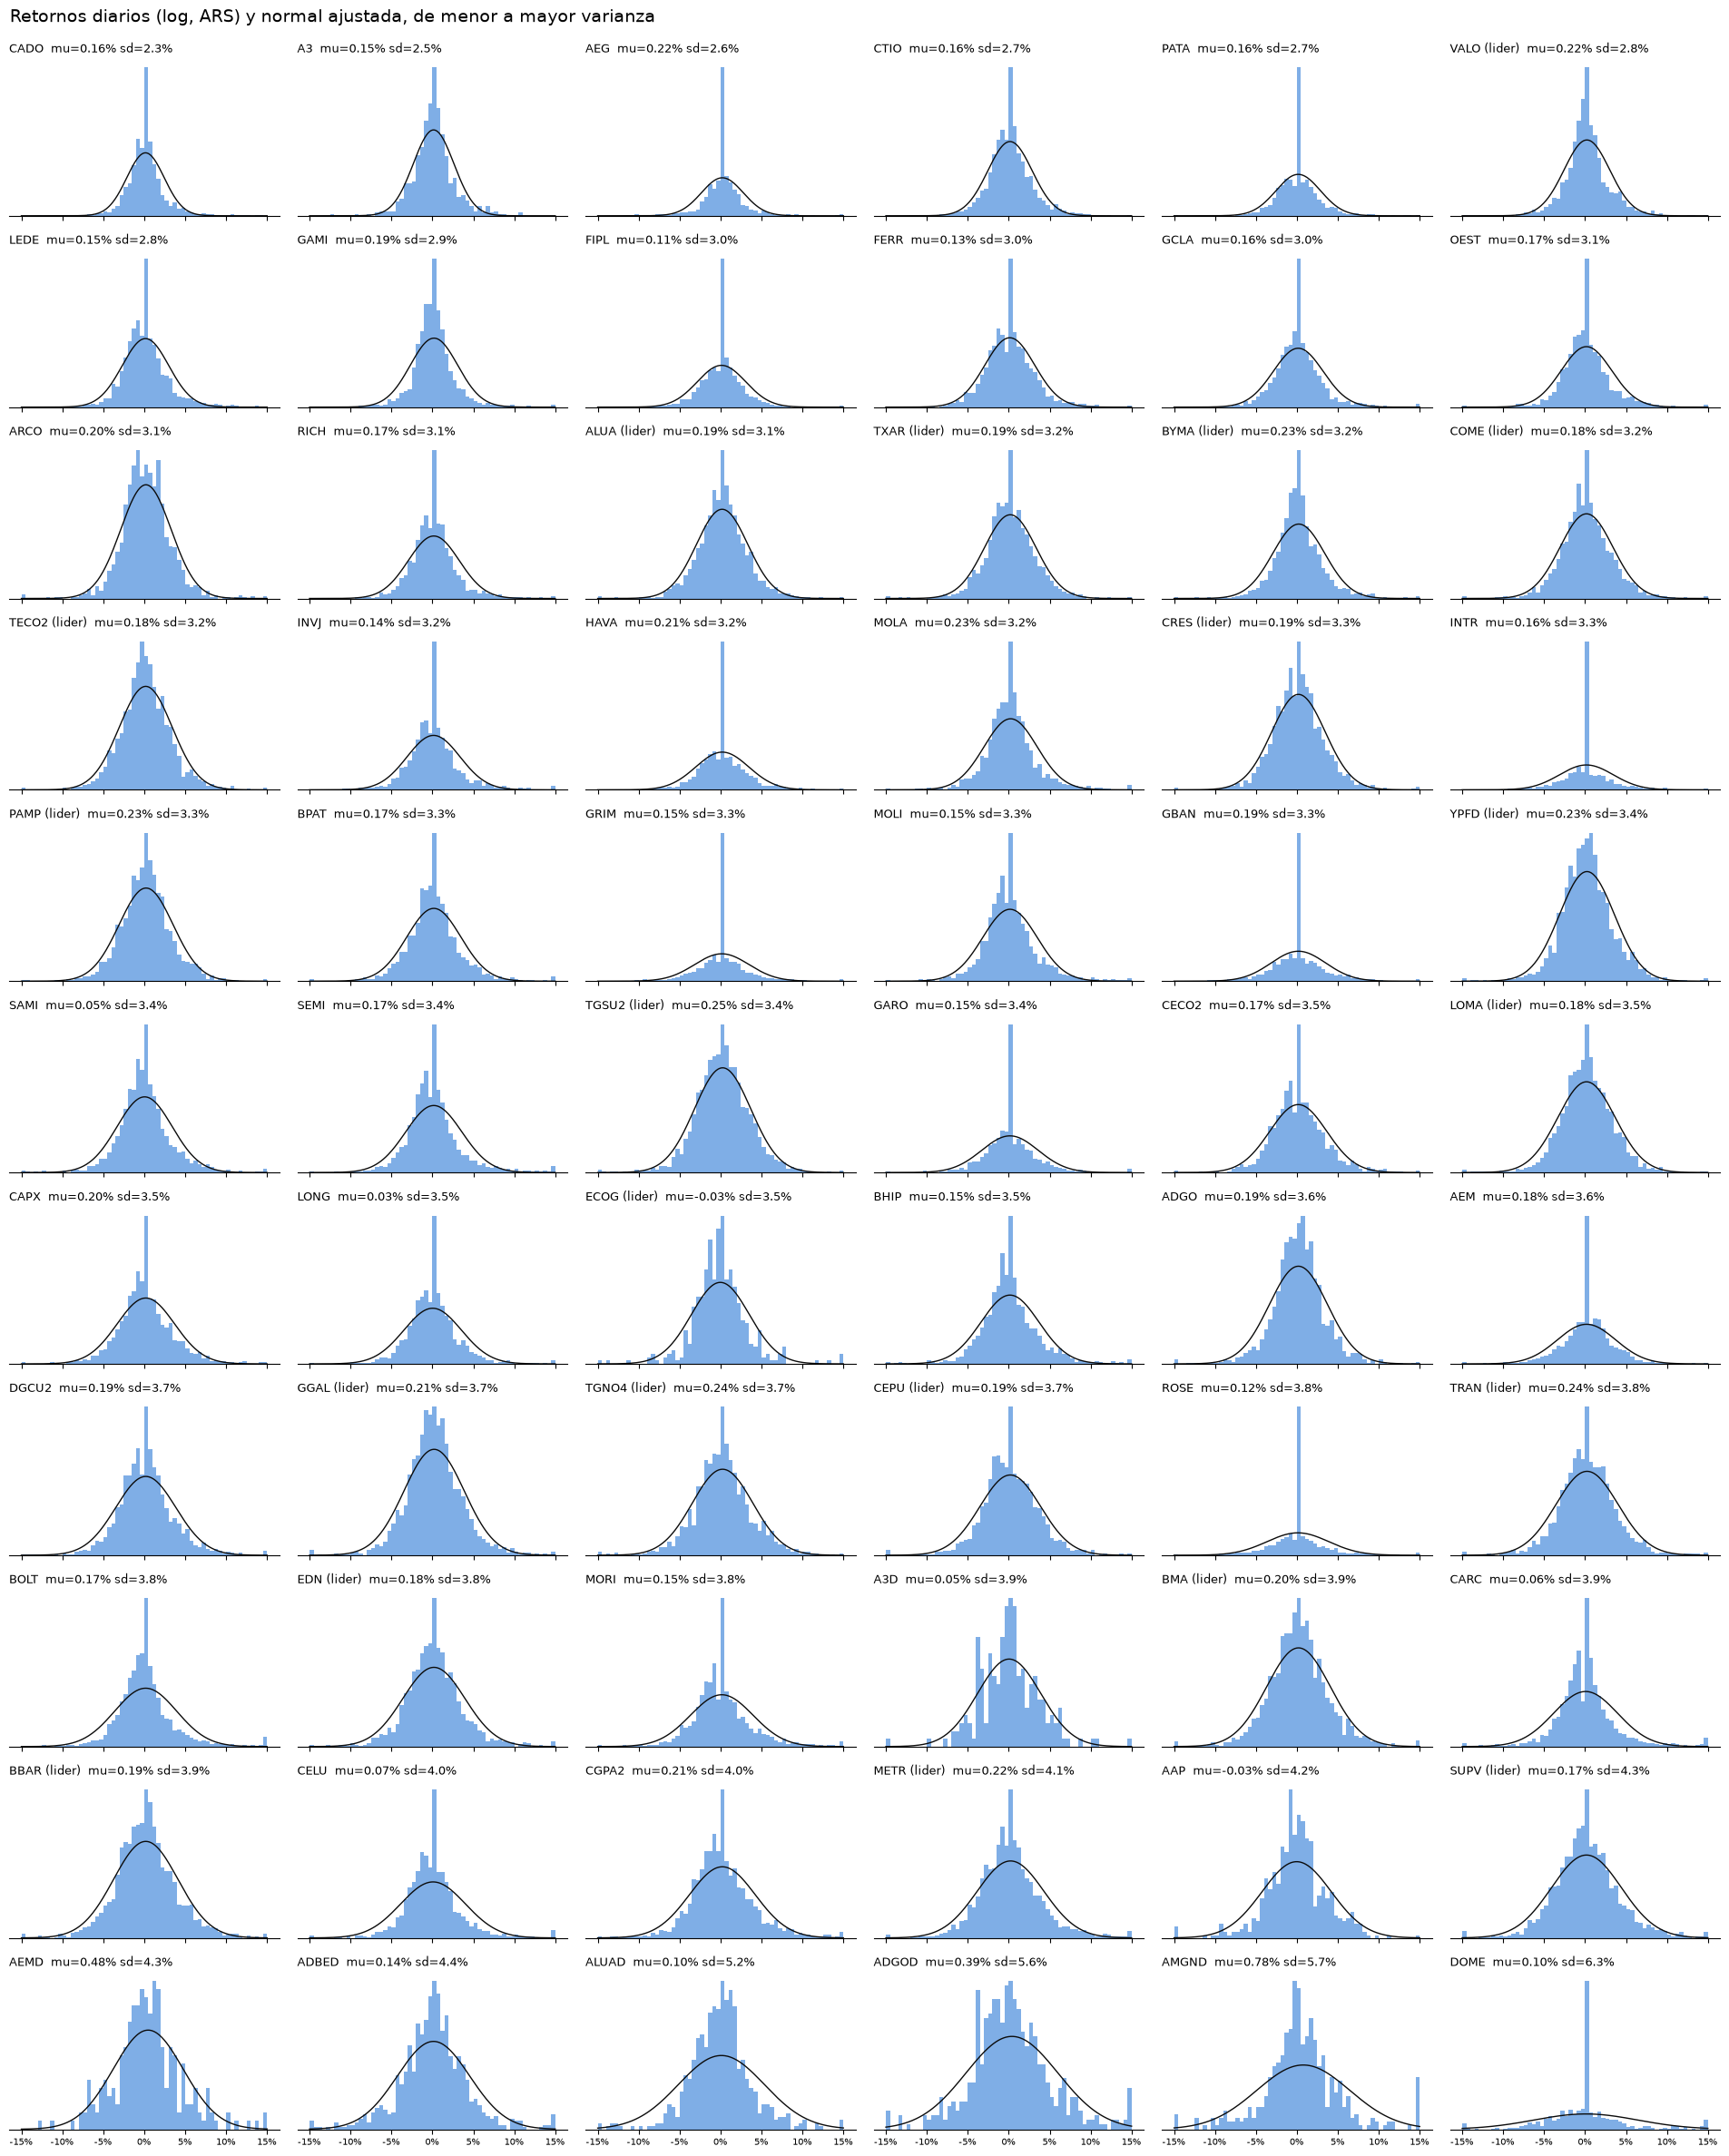

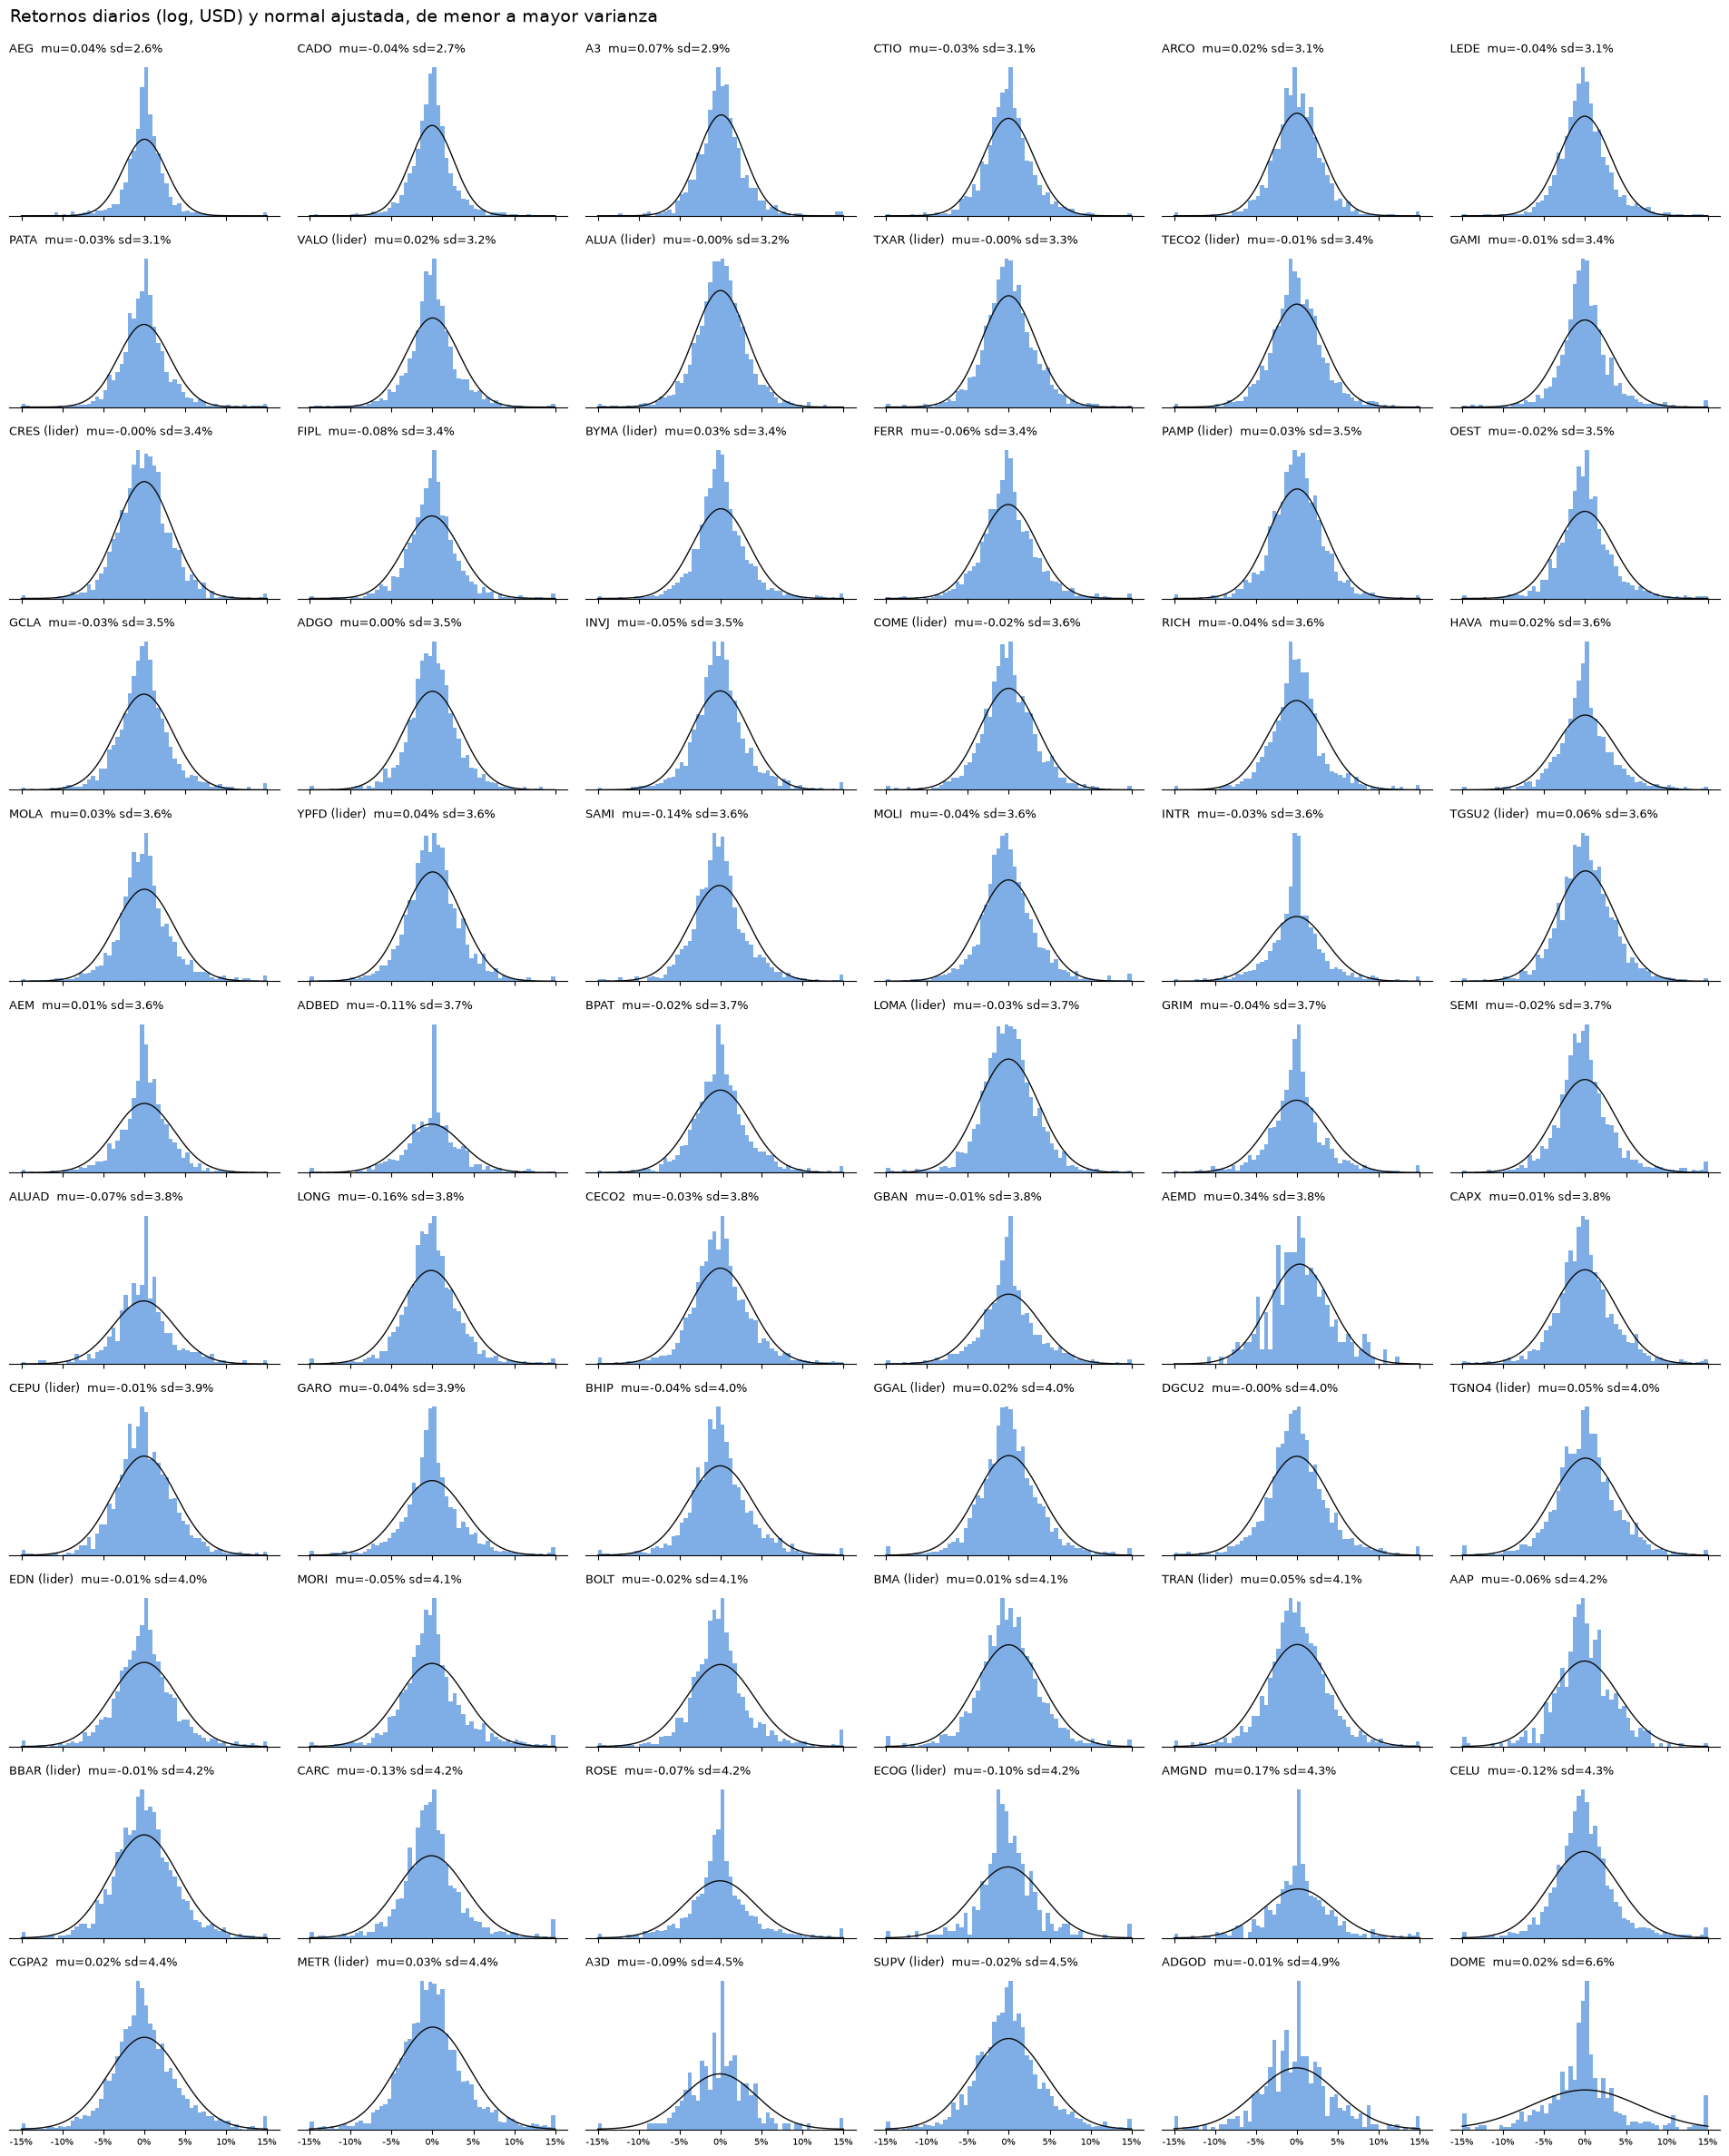

In [27]:
# Distribucion de los retornos diarios de cada accion (log) con la normal de igual media y desvio,
# ordenadas de menor a mayor varianza. Eje X recortado a +-15% para que se vea la forma;
# las colas mas largas se acumulan en las barras de los bordes.
LIMITE = 0.15
bins = np.linspace(-LIMITE, LIMITE, 61)
x = np.linspace(-LIMITE, LIMITE, 300)


def graficar_retornos(moneda: str) -> None:
    stats = dataset.groupby("ticker")[[f"media_{moneda}", f"desvio_{moneda}"]].first()
    stats = stats.join(info_tickers.set_index("ticker")["panel_lider"]).sort_values(f"desvio_{moneda}")
    n_filas = -(-len(stats) // n_cols)
    fig, axes = plt.subplots(n_filas, n_cols, figsize=(3.2 * n_cols, 2.2 * n_filas), sharex=True)
    for ax, (ticker, fila) in zip(axes.flat, stats.iterrows()):
        r = dataset.loc[dataset["ticker"] == ticker, f"retorno_{moneda}"].dropna()
        mu, sigma = fila[f"media_{moneda}"], fila[f"desvio_{moneda}"]
        ax.hist(r.clip(-LIMITE, LIMITE), bins=bins, density=True, color="#2a78d6", alpha=0.6)
        normal = np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))
        ax.plot(x, normal, color="#0b0b0b", linewidth=1)
        nombre = ticker + (" (lider)" if fila["panel_lider"] else "")
        ax.set_title(f"{nombre}  mu={mu * 100:.2f}% sd={sigma * 100:.1f}%", fontsize=9, loc="left")
        ax.tick_params(labelsize=7)
        ax.set_yticks([])
        ax.spines[["top", "right", "left"]].set_visible(False)
    for ax in axes.flat[len(stats):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.xaxis.set_major_formatter(lambda v, _: f"{v * 100:.0f}%")
    fig.suptitle(
        f"Retornos diarios (log, {moneda.upper()}) y normal ajustada, de menor a mayor varianza",
        fontsize=14, x=0.01, ha="left",
    )
    fig.tight_layout(rect=(0, 0, 1, 0.985))
    plt.show()


graficar_retornos("ars")
graficar_retornos("usd")

Devaluacion del CCL: 48.2% anual (log), desvio 29.0% anual
Mediana de las acciones: media 44.1% en ARS vs -3.7% en USD; desvio 54.7% en ARS vs 58.9% en USD


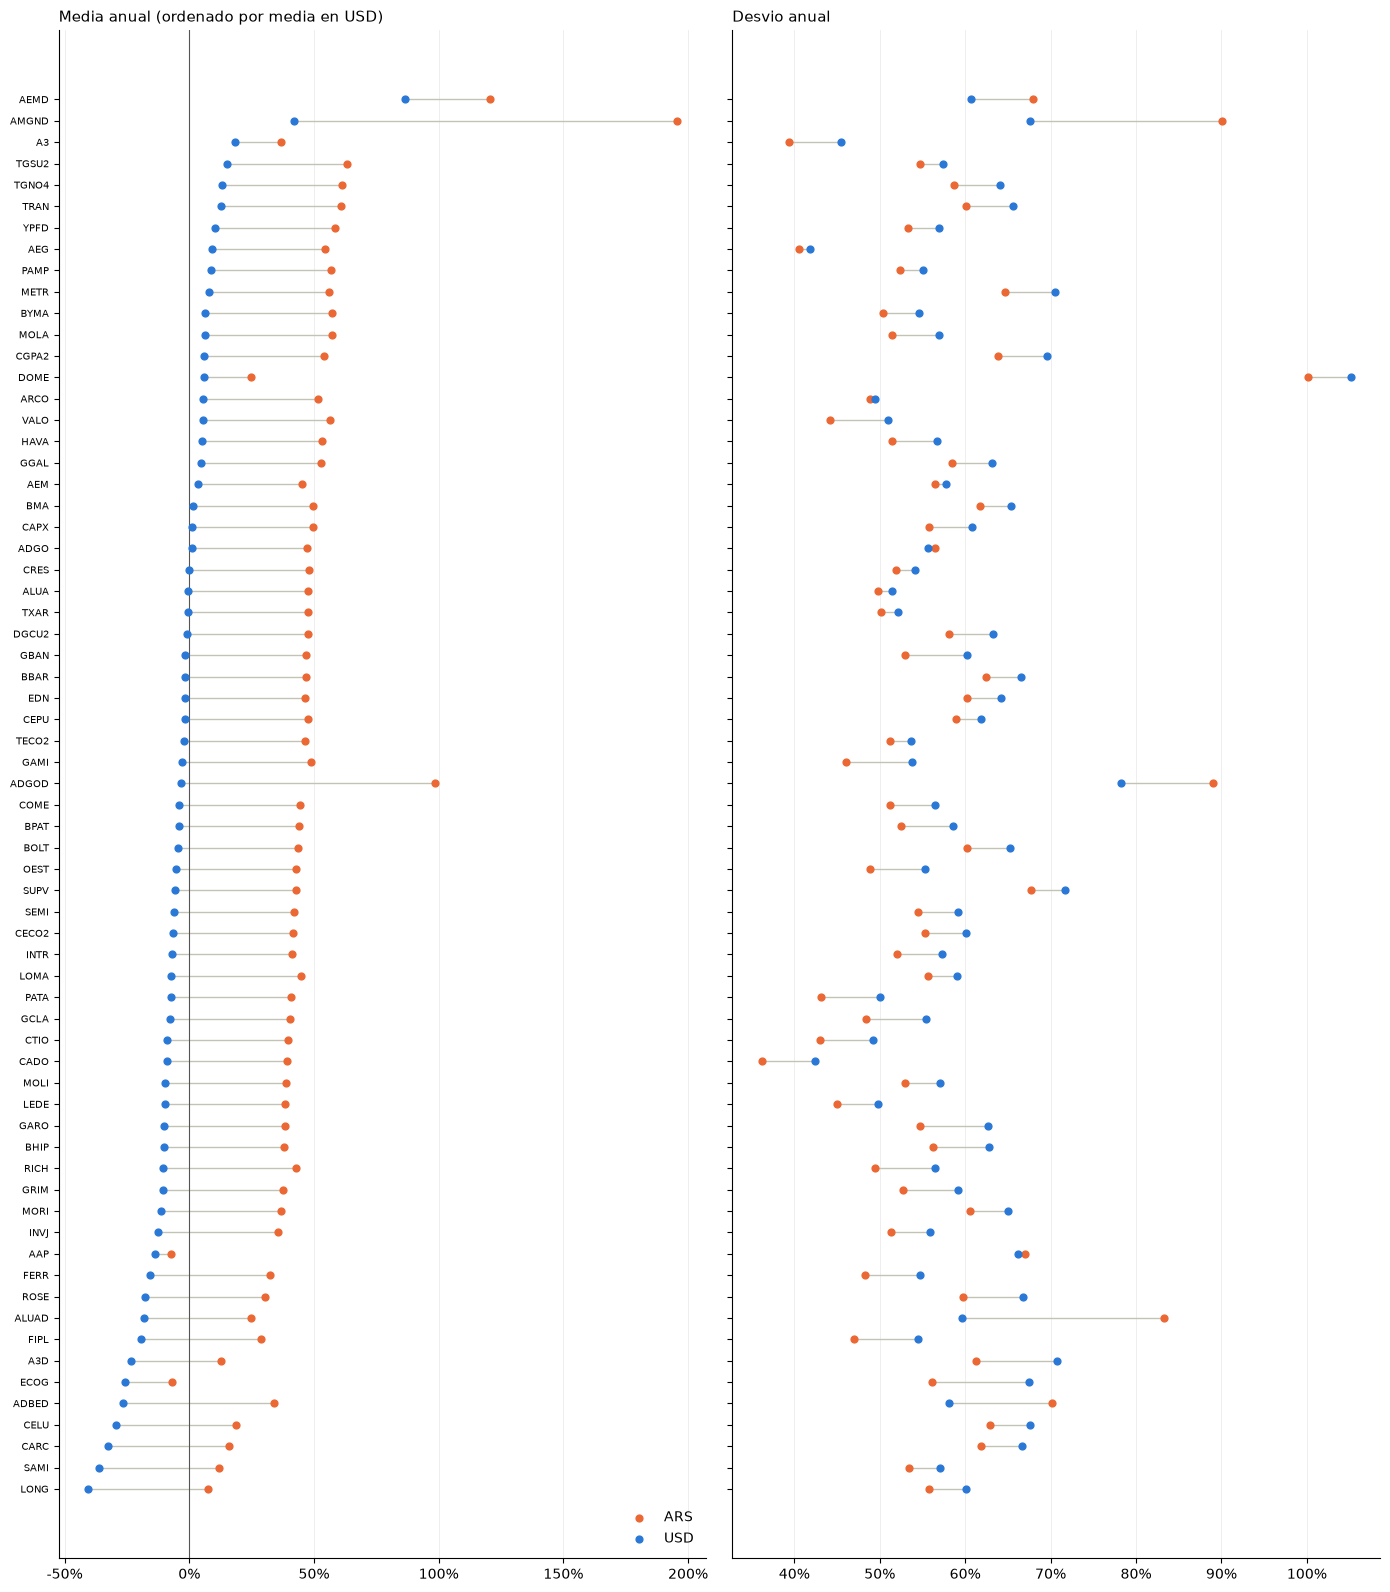

In [28]:
# Media y desvio anualizados de punta a punta, en ARS vs. en USD (media * 252, desvio * raiz(252)).
# La diferencia entre las dos medias es basicamente la devaluacion del CCL en el periodo de cada accion.
por_ticker = dataset.groupby("ticker")[["media_ars", "media_usd", "desvio_ars", "desvio_usd"]].first()
anual = pd.DataFrame(
    {
        "media_ars": por_ticker["media_ars"] * 252 * 100,
        "media_usd": por_ticker["media_usd"] * 252 * 100,
        "desvio_ars": por_ticker["desvio_ars"] * np.sqrt(252) * 100,
        "desvio_usd": por_ticker["desvio_usd"] * np.sqrt(252) * 100,
    }
).sort_values("media_usd")

# CCL de cada rueda (la serie de ArgentinaDatos es diaria calendario, se anualiza sobre ruedas)
r_ccl = np.log(dataset.groupby("fecha")["ccl_dia"].first()).diff()
print(f"Devaluacion del CCL: {r_ccl.mean() * 252 * 100:.1f}% anual (log), desvio {r_ccl.std() * np.sqrt(252) * 100:.1f}% anual")
print(f"Mediana de las acciones: media {anual['media_ars'].median():.1f}% en ARS vs {anual['media_usd'].median():.1f}% en USD; "
      f"desvio {anual['desvio_ars'].median():.1f}% en ARS vs {anual['desvio_usd'].median():.1f}% en USD")

fig, (ax_m, ax_d) = plt.subplots(1, 2, figsize=(14, 0.22 * len(anual) + 1.5), sharey=True)
y = np.arange(len(anual))
for ax, metrica in [(ax_m, "media"), (ax_d, "desvio")]:
    ax.hlines(y, anual[f"{metrica}_usd"], anual[f"{metrica}_ars"], color="#c3c2b7", linewidth=1)
    ax.scatter(anual[f"{metrica}_ars"], y, s=24, color="#eb6834", label="ARS", zorder=3)
    ax.scatter(anual[f"{metrica}_usd"], y, s=24, color="#2a78d6", label="USD", zorder=3)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
    ax.grid(axis="x", alpha=0.3, linewidth=0.5)
    ax.spines[["top", "right"]].set_visible(False)
ax_m.axvline(0, color="#555555", linewidth=0.8)
ax_m.set_yticks(y, anual.index, fontsize=7)
ax_m.set_title("Media anual (ordenado por media en USD)", fontsize=11, loc="left")
ax_d.set_title("Desvio anual", fontsize=11, loc="left")
ax_m.legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

# Features

In [29]:
# Universo: acciones locales en pesos (sin CEDEARs ni especies en dolares, que no tienen sector)
UNIVERSO = info_tickers.loc[info_tickers["sector"].notna() & ~info_tickers["en_dolares"], "ticker"]


def armar_features(df: pd.DataFrame) -> pd.DataFrame:
    """Features por ticker y fecha, todas con informacion hasta el cierre de esa fecha (en USD)."""
    df = df[df["ticker"].isin(UNIVERSO)].sort_values(["ticker", "fecha"])
    por_ticker = df.groupby("ticker")
    log_p = np.log(df["close_usd"])
    f = pd.DataFrame(index=df.index)

    # Precio: retornos pasados y distancia a medias moviles
    for k in (1, 5, 20, 60):
        f[f"ret_{k}"] = log_p - log_p.groupby(df["ticker"]).shift(k)
    for k in (20, 60):
        media_movil = por_ticker["close_usd"].rolling(k, min_periods=k).mean().droplevel(0)
        f[f"dist_ma{k}"] = log_p - np.log(media_movil)

    # Volatilidad realizada y su cambio (vol de corto plazo vs. largo plazo)
    for k in (5, 20, 60):
        f[f"vol_{k}"] = por_ticker["retorno_usd"].rolling(k, min_periods=k).std().droplevel(0)
    f["vol_ratio"] = f["vol_5"] / f["vol_60"]

    # Liquidez: volumen del dia contra su media de 20 ruedas
    volumen_medio = por_ticker["volume"].rolling(20, min_periods=20).mean().droplevel(0)
    f["volumen_rel"] = np.log1p(df["volume"]) - np.log1p(volumen_medio)

    # Mercado: beta y retorno a 5 ruedas del promedio del panel lider (mismo indice que beta_rolling)
    f["beta_252"] = df["beta_252"]
    mercado = df[df["panel_lider"]].groupby("fecha")["retorno_usd"].mean()
    f["mercado_ret_5"] = df["fecha"].map(mercado.rolling(5).sum())

    # Macro: columnas del dataset, ya corridas por su retraso de publicacion
    m = df.groupby("fecha")[["riesgo_pais", "ccl", "oficial", "tnx", "oil", "gold"]].first()
    macro = {
        "riesgo_pais_var_5": np.log(m["riesgo_pais"]).diff(5),
        "ccl_var_5": np.log(m["ccl"]).diff(5),
        "brecha": np.log(m["ccl"] / m["oficial"]),
        "tnx_var_5": m["tnx"].diff(5),
        "oil_ret_5": np.log(m["oil"].where(m["oil"] > 0)).diff(5),
        "gold_ret_5": np.log(m["gold"]).diff(5),
    }
    for nombre, serie in macro.items():
        f[nombre] = df["fecha"].map(serie)

    # Sector en one-hot
    f = f.join(pd.get_dummies(df["sector"], prefix="sector", dtype=float))
    return pd.concat([df[["fecha", "ticker", "close_usd"]], f], axis=1)


features = armar_features(dataset)
COLUMNAS_FEATURES = [c for c in features.columns if c not in ("fecha", "ticker", "close_usd")]
print(f"{features['ticker'].nunique()} tickers, {len(features)} filas, {len(COLUMNAS_FEATURES)} features")
features[COLUMNAS_FEATURES].describe().T.round(3)

55 tickers, 126783 filas, 30 features


,count,mean,std,min,25%,50%,75%,max
ret_1,126728.0,-0.000,0.038,-0.695,-0.019,-0.001,0.017,0.553
ret_5,126508.0,-0.001,0.088,-1.000,-0.046,-0.004,0.041,1.069
ret_20,125683.0,-0.003,0.178,-1.467,-0.099,-0.010,0.089,1.351
ret_60,123483.0,-0.007,0.303,-1.801,-0.184,-0.012,0.175,1.486
dist_ma20,125738.0,-0.004,0.098,-1.010,-0.053,-0.006,0.046,0.996
dist_ma60,123538.0,-0.012,0.176,-1.383,-0.105,-0.012,0.090,1.253
vol_5,126508.0,0.031,0.021,0.000,0.017,0.026,0.038,0.325
vol_20,125683.0,0.034,0.016,0.004,0.023,0.030,0.040,0.183
vol_60,123483.0,0.035,0.014,0.007,0.026,0.032,0.041,0.122
vol_ratio,123483.0,0.890,0.452,0.000,0.562,0.817,1.134,3.561


In [30]:
# Target: retorno USD a 5 ruedas comparado con la volatilidad esperada (vol de 20 ruedas, conocida en t)
#   baja (0) si z < -K, neutral (1) en el medio, sube (2) si z > K, con z = retorno / sigma.
# K se fija con train para que las tres clases queden parejas.
HORIZONTE = 5
FIN_TRAIN, FIN_VAL = pd.Timestamp("2022-12-31"), pd.Timestamp("2024-12-31")
CLASES = ["baja", "neutral", "sube"]

log_p = np.log(features["close_usd"])
features["ret_fut"] = log_p.groupby(features["ticker"]).shift(-HORIZONTE) - log_p
features["sigma"] = features["vol_20"] * np.sqrt(HORIZONTE)
z = features["ret_fut"] / features["sigma"]

K = z[features["fecha"] <= FIN_TRAIN].abs().quantile(1 / 3)
features["clase"] = np.select([z < -K, z > K], [0, 2], 1).astype(float)
features.loc[z.isna(), "clase"] = np.nan

periodo = pd.cut(features["fecha"], [pd.Timestamp.min, FIN_TRAIN, FIN_VAL, pd.Timestamp.max], labels=["train", "val", "test"])
print(f"K = {K:.3f} desvios")
(pd.crosstab(periodo, features["clase"].map(dict(enumerate(CLASES))), normalize="index") * 100).round(1)

K = 0.392 desvios


clase,baja,neutral,sube
fecha,,,
train,35.1,33.3,31.6
val,30.8,32.6,36.6
test,41.4,32.8,25.8


# Red neuronal

In [31]:
# Split temporal con purga: se sacan las ultimas HORIZONTE ruedas de train y de val, porque su target
# mira dias que ya pertenecen al bloque siguiente. Winsorizado y escalado con parametros de train.
datos = features.dropna(subset=COLUMNAS_FEATURES + ["clase"])
fechas = np.sort(datos["fecha"].unique())


def bloque(desde, hasta, purgar: bool) -> pd.DataFrame:
    en_bloque = fechas[(fechas > desde) & (fechas <= hasta)]
    if purgar:
        en_bloque = en_bloque[:-HORIZONTE]
    return datos[datos["fecha"].isin(en_bloque)]


train = bloque(pd.Timestamp.min, FIN_TRAIN, purgar=True)
val = bloque(FIN_TRAIN, FIN_VAL, purgar=True)
test = bloque(FIN_VAL, pd.Timestamp.max, purgar=False)

bajo, alto = train[COLUMNAS_FEATURES].quantile(0.01), train[COLUMNAS_FEATURES].quantile(0.99)
recortado = train[COLUMNAS_FEATURES].clip(bajo, alto, axis=1)
media, desvio = recortado.mean(), recortado.std().replace(0, 1)


def preparar(bloque_df: pd.DataFrame):
    x = ((bloque_df[COLUMNAS_FEATURES].clip(bajo, alto, axis=1) - media) / desvio).to_numpy("float32")
    return x, bloque_df["clase"].to_numpy("int64")


X_train, y_train = preparar(train)
X_val, y_val = preparar(val)
X_test, y_test = preparar(test)
for nombre, b in [("train", train), ("val", val), ("test", test)]:
    print(f"{nombre:5s} {len(b):6d} filas  {b['fecha'].min().date()} -> {b['fecha'].max().date()}")

train  69762 filas  2017-04-26 -> 2022-12-23
val    25319 filas  2023-01-02 -> 2024-12-20
test   23787 filas  2025-01-02 -> 2026-10-15


In [32]:
os.environ["KERAS_BACKEND"] = "torch"  # Keras 3 sobre PyTorch (no hay TensorFlow en el entorno)
# En CPU: la GPU de esta PC no es compatible con el build de torch, y para un MLP chico alcanza
os.environ["CUDA_VISIBLE_DEVICES"] = ""
import keras


def armar_modelo(capas=(64, 32), dropout=0.3, lr=1e-3, l2=1e-4) -> keras.Model:
    """MLP para 3 clases. Con ``capas=()`` queda una regresion logistica (baseline lineal)."""
    modelo = keras.Sequential([keras.layers.Input(shape=(len(COLUMNAS_FEATURES),))])
    for n in capas:
        modelo.add(keras.layers.Dense(n, activation="relu", kernel_regularizer=keras.regularizers.l2(l2)))
        modelo.add(keras.layers.Dropout(dropout))
    modelo.add(keras.layers.Dense(len(CLASES), activation="softmax"))
    modelo.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return modelo


armar_modelo().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,163 (16.26 KB)

 Trainable params: 4,163 (16.26 KB)

 Non-trainable params: 0 (0.00 B)

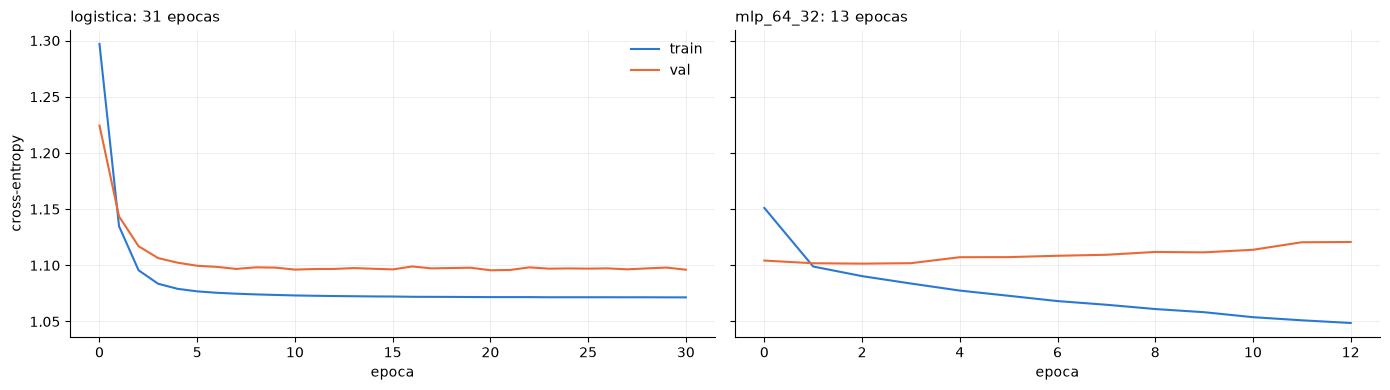

In [33]:
def entrenar(modelo: keras.Model, epocas: int = 200, batch: int = 512):
    """Entrena con EarlyStopping sobre la perdida de validacion y devuelve el historial."""
    corte = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    return modelo.fit(
        X_train, y_train, validation_data=(X_val, y_val),
        epochs=epocas, batch_size=batch, callbacks=[corte], verbose=0,
    ).history


keras.utils.set_random_seed(42)
modelos = {"logistica": armar_modelo(capas=()), "mlp_64_32": armar_modelo()}
historiales = {nombre: entrenar(m) for nombre, m in modelos.items()}

fig, axes = plt.subplots(1, len(modelos), figsize=(14, 4), sharey=True)
for ax, (nombre, h) in zip(axes, historiales.items()):
    ax.plot(h["loss"], color="#2a78d6", label="train")
    ax.plot(h["val_loss"], color="#eb6834", label="val")
    ax.set_title(f"{nombre}: {len(h['loss'])} epocas", fontsize=11, loc="left")
    ax.set_xlabel("epoca")
    ax.grid(alpha=0.3, linewidth=0.5)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("cross-entropy")
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

In [34]:
def matriz_confusion(real: np.ndarray, pred: np.ndarray) -> np.ndarray:
    """Conteos [clase real, clase predicha]."""
    m = np.zeros((len(CLASES), len(CLASES)), dtype=int)
    np.add.at(m, (real, pred), 1)
    return m


def f1_macro(real: np.ndarray, pred: np.ndarray) -> float:
    m = matriz_confusion(real, pred)
    precision = np.diag(m) / np.maximum(m.sum(axis=0), 1)
    recall = np.diag(m) / np.maximum(m.sum(axis=1), 1)
    return float(np.mean(2 * precision * recall / np.maximum(precision + recall, 1e-12)))


# Evaluacion en validacion (el test queda guardado para el final)
clase_mayoritaria = np.bincount(y_train).argmax()
predicciones = {"clase_mayoritaria": np.full_like(y_val, clase_mayoritaria)}
predicciones |= {nombre: m.predict(X_val, verbose=0).argmax(axis=1) for nombre, m in modelos.items()}

metricas = pd.DataFrame(
    {
        nombre: {
            "accuracy": (pred == y_val).mean(),
            "f1_macro": f1_macro(y_val, pred),
            **{f"% predice {c}": (pred == i).mean() * 100 for i, c in enumerate(CLASES)},
        }
        for nombre, pred in predicciones.items()
    }
).T
display(metricas.round(3))

# Matriz de confusion del MLP, normalizada por la clase real (cada fila suma 100%)
conteos = matriz_confusion(y_val, predicciones["mlp_64_32"])
confusion = conteos / conteos.sum(axis=1, keepdims=True) * 100
pd.DataFrame(confusion, index=[f"real {c}" for c in CLASES], columns=[f"pred {c}" for c in CLASES]).round(1)

,accuracy,f1_macro,% predice baja,% predice neutral,% predice sube
clase_mayoritaria,0.308,0.157,100.000,0.00,0.000
logistica,0.385,0.382,34.792,41.04,24.168
mlp_64_32,0.360,0.358,42.936,34.50,22.564


,pred baja,pred neutral,pred sube
real baja,43.5,34.8,21.8
real neutral,38.7,41.0,20.3
real sube,46.3,28.5,25.2


In [35]:
import itertools
import time

# Grilla chica con mas regularizacion; cada configuracion con varias semillas, porque con una senal
# tan debil dos corridas de la misma red pueden diferir mas que dos configuraciones distintas.
# Se elige mirando solo validacion.
GRILLA = {
    "capas": [(), (16,), (32, 16), (64, 32)],
    "dropout": [0.3, 0.5],
    "l2": [1e-4, 1e-3],
}
SEMILLAS = [0, 1, 2]

corridas = []
inicio = time.time()
for capas, dropout, l2 in itertools.product(*GRILLA.values()):
    if not capas and dropout != GRILLA["dropout"][0]:
        continue  # sin capas intermedias el dropout no se usa: la logistica va una sola vez por l2
    for semilla in SEMILLAS:
        keras.utils.set_random_seed(semilla)
        modelo = armar_modelo(capas=capas, dropout=dropout, l2=l2)
        h = entrenar(modelo)
        pred = modelo.predict(X_val, verbose=0).argmax(axis=1)
        corridas.append(
            {
                "capas": str(capas) if capas else "logistica",
                "dropout": dropout if capas else np.nan,
                "l2": l2,
                "semilla": semilla,
                "epocas": len(h["loss"]),
                "val_loss": min(h["val_loss"]),
                "accuracy": (pred == y_val).mean(),
                "f1_macro": f1_macro(y_val, pred),
            }
        )
print(f"{len(corridas)} corridas en {time.time() - inicio:.0f} s")

resultados_grilla = (
    pd.DataFrame(corridas)
    .groupby(["capas", "dropout", "l2"], dropna=False)[["epocas", "val_loss", "accuracy", "f1_macro"]]
    .agg(["mean", "std"])
    .sort_values(("val_loss", "mean"))
)
resultados_grilla.round(4)

42 corridas en 307 s


epocas         val_loss         accuracy         f1_macro        
                             mean     std     mean     std     mean     std     mean     std
capas     dropout l2                                                                        
logistica NaN     0.0001  20.3333  4.1633   1.0954  0.0006   0.3834  0.0017   0.3813  0.0014
                  0.0010  20.3333  4.1633   1.0954  0.0006   0.3834  0.0017   0.3813  0.0014
(32, 16)  0.5     0.0001  23.3333  4.0415   1.0979  0.0010   0.3600  0.0026   0.3535  0.0066
(16,)     0.5     0.0001  15.3333  1.5275   1.0987  0.0010   0.3635  0.0041   0.3602  0.0022
(32, 16)  0.3     0.0001  16.0000  1.7321   1.1002  0.0023   0.3606  0.0037   0.3536  0.0048
(16,)     0.3     0.0001  17.3333  3.2146   1.1002  0.0016   0.3704  0.0042   0.3693  0.0043
(64, 32)  0.5     0.0001  18.0000  1.0000   1.1020  0.0026   0.3600  0.0025   0.3471  0.0090
(16,)     0.5     0.0010  20.3333  3.0551   1.1027  0.0004   0.3679  0.0055   0.3650  0.0052
(64, 32)  0.3     0.0001  12.3333  1.5275   1.1047  0.0032   0.3584  0.0071   0.3499  0.0171
(16,)     0.3     0.0010  19.0000  2.0000   1.1051  0.0015   0.3699  0.0057   0.3684  0.0054
(32, 16)  0.5     0.0010  22.0000  1.7321   1.1059  0.0013   0.3601  0.0021   0.3528  0.0025
          0.3     0.0010  21.0000  1.7321   1.1111  0.0023   0.3685  0.0013   0.3652  0.0035
(64, 32)  0.5     0.0010  21.6667  1.5275   1.1120  0.0022   0.3718  0.0024   0.3672  0.0013
          0.3     0.0010  19.3333  2.0817   1.1221  0.0030   0.3771  0.0041   0.3726  0.0051